In [1]:

# PHASE 0 — Environment setup
# Run this before downloading or processing any data.

import sys
import os
import json
import importlib.util
import subprocess
from pathlib import Path
from datetime import datetime, timezone

required_packages = {
    "gwpy": "gwpy",
    "pycbc": "pycbc",
    "gwosc": "gwosc",
    "h5py": "h5py",
    "scipy": "scipy",
    "sklearn": "scikit-learn",
    "matplotlib": "matplotlib",
    "pandas": "pandas",
}

missing_packages = [
    package
    for module, package in required_packages.items()
    if importlib.util.find_spec(module) is None
]

print("Missing packages:", missing_packages or "None")

if missing_packages:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        *missing_packages
    ])

# Create a clean project structure.
PROJECT_DIR = Path("/content/gw150914_flagship")

folders = [
    "raw",
    "processed",
    "figures",
    "models",
    "reports",
    "logs",
]

for folder in folders:
    (PROJECT_DIR / folder).mkdir(parents=True, exist_ok=True)

# Verify imports and record software versions.
import numpy as np
import scipy
import matplotlib
import pandas as pd
import gwpy
import pycbc
import gwosc
import h5py
import sklearn

environment = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "python": sys.version,
    "numpy": np.__version__,
    "scipy": scipy.__version__,
    "matplotlib": matplotlib.__version__,
    "pandas": pd.__version__,
    "gwpy": gwpy.__version__,
    "pycbc": pycbc.__version__,
    "gwosc": getattr(gwosc, "__version__", "not exposed"),
    "h5py": h5py.__version__,
    "scikit_learn": sklearn.__version__,
}

with open(PROJECT_DIR / "logs" / "environment.json", "w") as f:
    json.dump(environment, f, indent=2)

print("\nProject directory:", PROJECT_DIR)
print("\nEnvironment verification:")
for package, version in environment.items():
    print(f"{package}: {version}")

print("\nPHASE 0 COMPLETE")
print("Environment record saved.")


Missing packages: ['gwpy', 'pycbc', 'gwosc']


/usr/local/lib/python3.13/dist-packages/gwpy/time/_ligotimegps.py:42: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  from lal import LIGOTimeGPS



Project directory: /content/gw150914_flagship

Environment verification:
created_utc: 2026-10-27T12:13:31.329348+00:00
python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
numpy: 2.1.3
scipy: 1.16.3
matplotlib: 3.10.0
pandas: 2.2.3
gwpy: 4.1.0
pycbc: 2.11.0
gwosc: 0.8.3
h5py: 3.14.0
scikit_learn: 1.6.1

PHASE 0 COMPLETE
Environment record saved.


In [2]:

# PHASE 1A — Download the GW150914 event data
# Official public data through GWOSC using GWpy.

import json
import numpy as np
from pathlib import Path
from gwpy.timeseries import TimeSeries

PROJECT_DIR = Path("/content/gw150914_flagship")
RAW_DIR = PROJECT_DIR / "raw"
REPORT_DIR = PROJECT_DIR / "reports"

# GW150914 event GPS time
EVENT_GPS = 1126259462.4
SAMPLE_RATE = 4096
HALF_DURATION = 16

START_GPS = EVENT_GPS - HALF_DURATION
END_GPS = EVENT_GPS + HALF_DURATION

event_data = {}
manifest = {
    "event": "GW150914",
    "event_gps": EVENT_GPS,
    "requested_start_gps": START_GPS,
    "requested_end_gps": END_GPS,
    "requested_sample_rate_hz": SAMPLE_RATE,
    "source": "GWOSC public strain data via GWpy",
    "detectors": {}
}

for detector in ["H1", "L1"]:
    print(f"\nDownloading {detector}...")

    try:
        strain = TimeSeries.fetch_open_data(
            detector,
            START_GPS,
            END_GPS,
            sample_rate=SAMPLE_RATE,
            cache=True
        )

        values = np.asarray(strain.value, dtype=np.float64)

        # Verify the returned data before saving.
        assert len(values) > 0, f"{detector}: empty data"
        assert np.isfinite(values).all(), (
            f"{detector}: non-finite samples found"
        )

        actual_rate = float(strain.sample_rate.value)
        actual_start = float(strain.t0.value)
        actual_end = float(strain.times.value[-1])

        # Save unfiltered strain, with metadata.
        np.save(RAW_DIR / f"{detector}_GW150914_raw.npy", values)

        event_data[detector] = strain

        manifest["detectors"][detector] = {
            "sample_count": int(len(values)),
            "sample_rate_hz": actual_rate,
            "start_gps": actual_start,
            "last_sample_gps": actual_end,
            "duration_seconds": float(len(values) / actual_rate),
            "finite_values": True,
            "standard_deviation": float(np.std(values)),
            "raw_file": f"{detector}_GW150914_raw.npy"
        }

        print("Download and basic validation successful.")
        print("Samples:", len(values))
        print("Sampling rate:", actual_rate, "Hz")
        print("Start GPS:", actual_start)
        print("Last sample GPS:", actual_end)
        print("Standard deviation:", np.std(values))

    except Exception as exc:
        print(f"{detector} DOWNLOAD/VALIDATION FAILED")
        print(type(exc).__name__, str(exc))
        raise

with open(REPORT_DIR / "GW150914_event_manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)

print("\nPHASE 1A COMPLETE")
print("Raw files saved in:", RAW_DIR)
print("Manifest saved in:", REPORT_DIR)
print("Do not filter or overwrite the raw files.")



Download and basic validation successful.
Samples: 131072
Sampling rate: 4096.0 Hz
Start GPS: 1126259446.3999023
Last sample GPS: 1126259478.3996582
Standard deviation: 2.2158934597034714e-19

Download and basic validation successful.
Samples: 131072
Sampling rate: 4096.0 Hz
Start GPS: 1126259446.3999023
Last sample GPS: 1126259478.3996582
Standard deviation: 2.3277355999658365e-19

PHASE 1A COMPLETE
Raw files saved in: /content/gw150914_flagship/raw
Manifest saved in: /content/gw150914_flagship/reports
Do not filter or overwrite the raw files.


In [3]:

# PHASE 1B — Download independent candidate background segments
# Preserve raw strain. Do not filter or whiten it here.

import json
import numpy as np
from pathlib import Path
from gwpy.timeseries import TimeSeries

PROJECT_DIR = Path("/content/gw150914_flagship")
RAW_DIR = PROJECT_DIR / "raw"
REPORT_DIR = PROJECT_DIR / "reports"

EVENT_GPS = 1126259462.4
SAMPLE_RATE = 4096
SEGMENT_DURATION = 128

# Each number is the time separation, in seconds, between
# the event GPS time and the CENTER of a candidate segment.
OFFSETS_SECONDS = [300, 600, 900, 1200]

background_manifest = {
    "event": "GW150914",
    "source": "GWOSC public strain data via GWpy",
    "sample_rate_hz_requested": SAMPLE_RATE,
    "segment_duration_seconds_requested": SEGMENT_DURATION,
    "selection_note": (
        "Candidate off-source periods. Not yet certified glitch-free "
        "or confirmed suitable for training."
    ),
    "segments": []
}

for offset in OFFSETS_SECONDS:
    center_gps = EVENT_GPS - offset
    start_gps = center_gps - SEGMENT_DURATION / 2
    end_gps = center_gps + SEGMENT_DURATION / 2

    print(
        f"\nCandidate offset: {offset}s | "
        f"GPS interval: {start_gps:.3f} to {end_gps:.3f}"
    )

    record = {
        "offset_before_event_seconds": offset,
        "requested_start_gps": start_gps,
        "requested_end_gps": end_gps,
        "detectors": {}
    }

    for detector in ["H1", "L1"]:
        print(f"  Downloading {detector}...")

        strain = TimeSeries.fetch_open_data(
            detector,
            start_gps,
            end_gps,
            sample_rate=SAMPLE_RATE,
            cache=True
        )

        values = np.asarray(strain.value, dtype=np.float64)
        actual_rate = float(strain.sample_rate.value)

        # Basic checks only; these do not establish glitch-free data.
        assert len(values) > 0, f"{detector}: empty segment"
        assert np.isfinite(values).all(), (
            f"{detector}: non-finite values"
        )
        assert actual_rate == SAMPLE_RATE, (
            f"{detector}: unexpected sampling rate {actual_rate}"
        )

        expected_samples = SEGMENT_DURATION * SAMPLE_RATE
        assert len(values) == expected_samples, (
            f"{detector}: expected {expected_samples} samples, "
            f"received {len(values)}"
        )

        filename = f"{detector}_background_offset_{offset}s.npy"
        np.save(RAW_DIR / filename, values)

        record["detectors"][detector] = {
            "file": filename,
            "sample_count": int(len(values)),
            "sample_rate_hz": actual_rate,
            "actual_start_gps": float(strain.t0.value),
            "last_sample_gps": float(strain.times.value[-1]),
            "finite_values": True,
            "mean": float(np.mean(values)),
            "standard_deviation": float(np.std(values))
        }

        print(
            f"  {detector}: saved {len(values)} samples; "
            f"std={np.std(values):.4e}"
        )

    # Save progress after every paired segment.
    background_manifest["segments"].append(record)

    with open(
        REPORT_DIR / "candidate_background_manifest.json", "w"
    ) as f:
        json.dump(background_manifest, f, indent=2)

print("\nPHASE 1B COMPLETE")
print("Background files:", RAW_DIR)
print(
    "Manifest:",
    REPORT_DIR / "candidate_background_manifest.json"
)
print("Next: inspect the downloaded segments and their data quality.")



Candidate offset: 300s | GPS interval: 1126259098.400 to 1126259226.400
  H1: saved 524288 samples; std=2.1172e-19
  L1: saved 524288 samples; std=2.2503e-19

Candidate offset: 600s | GPS interval: 1126258798.400 to 1126258926.400
  H1: saved 524288 samples; std=2.1052e-19
  L1: saved 524288 samples; std=2.3276e-19

Candidate offset: 900s | GPS interval: 1126258498.400 to 1126258626.400
  H1: saved 524288 samples; std=2.0265e-19
  L1: saved 524288 samples; std=2.1673e-19

Candidate offset: 1200s | GPS interval: 1126258198.400 to 1126258326.400
  H1: saved 524288 samples; std=2.1155e-19
  L1: saved 524288 samples; std=2.0723e-19

PHASE 1B COMPLETE
Background files: /content/gw150914_flagship/raw
Manifest: /content/gw150914_flagship/reports/candidate_background_manifest.json
Next: inspect the downloaded segments and their data quality.


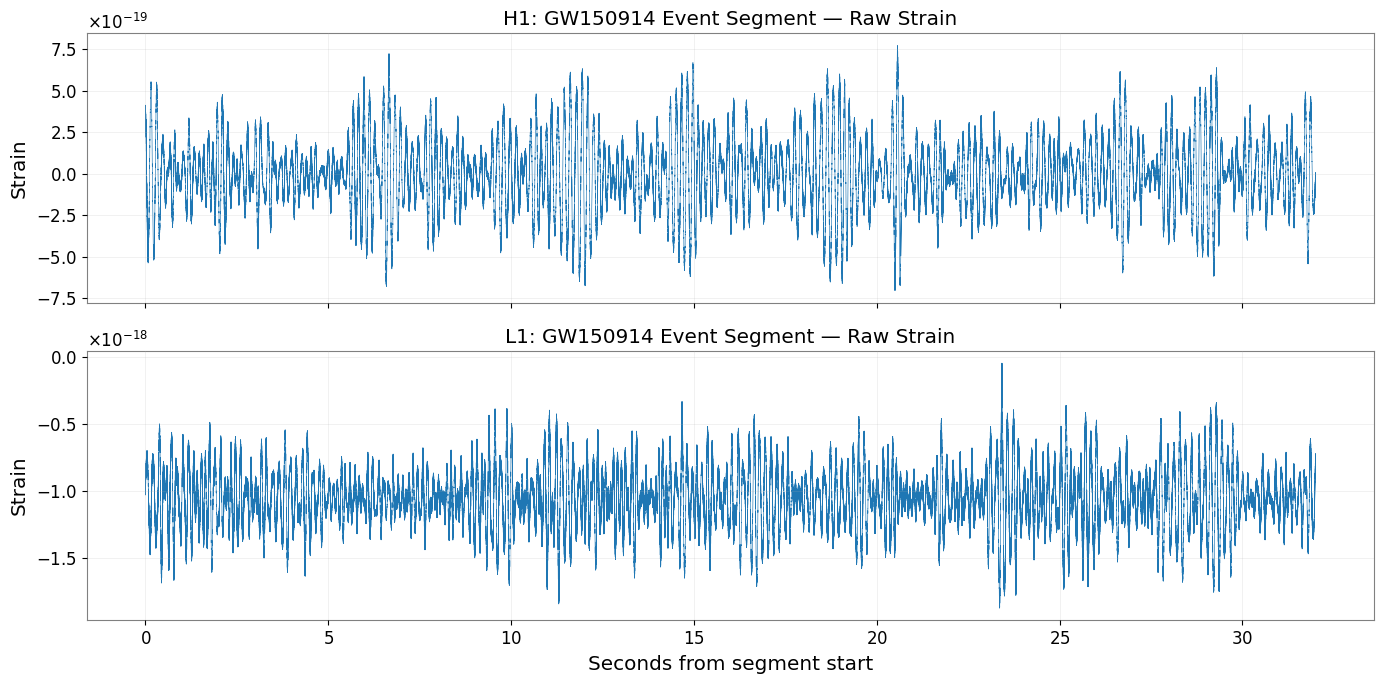

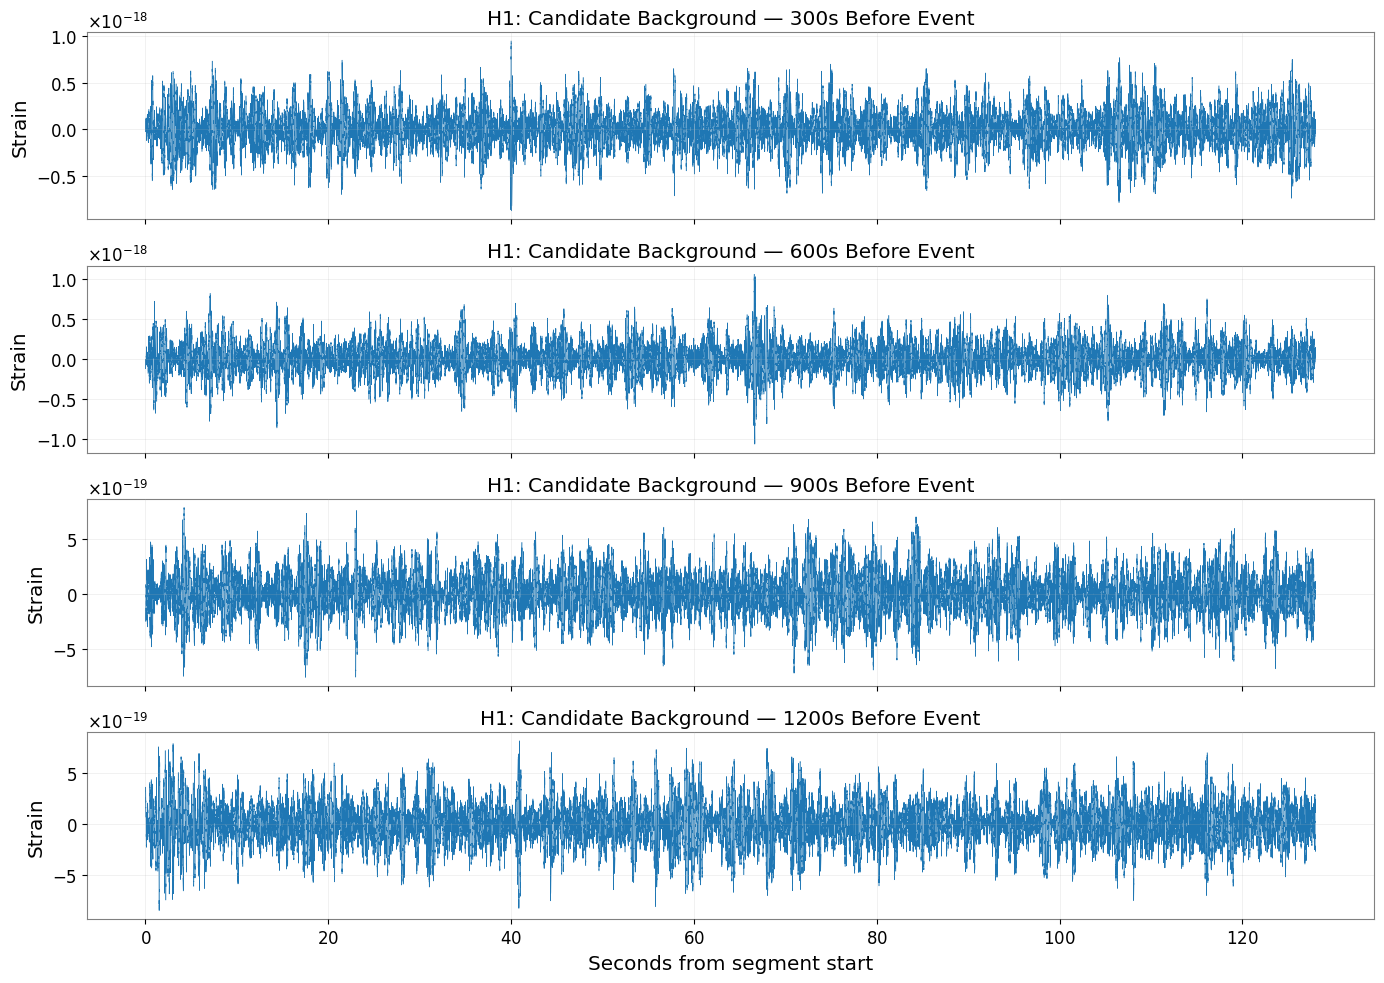

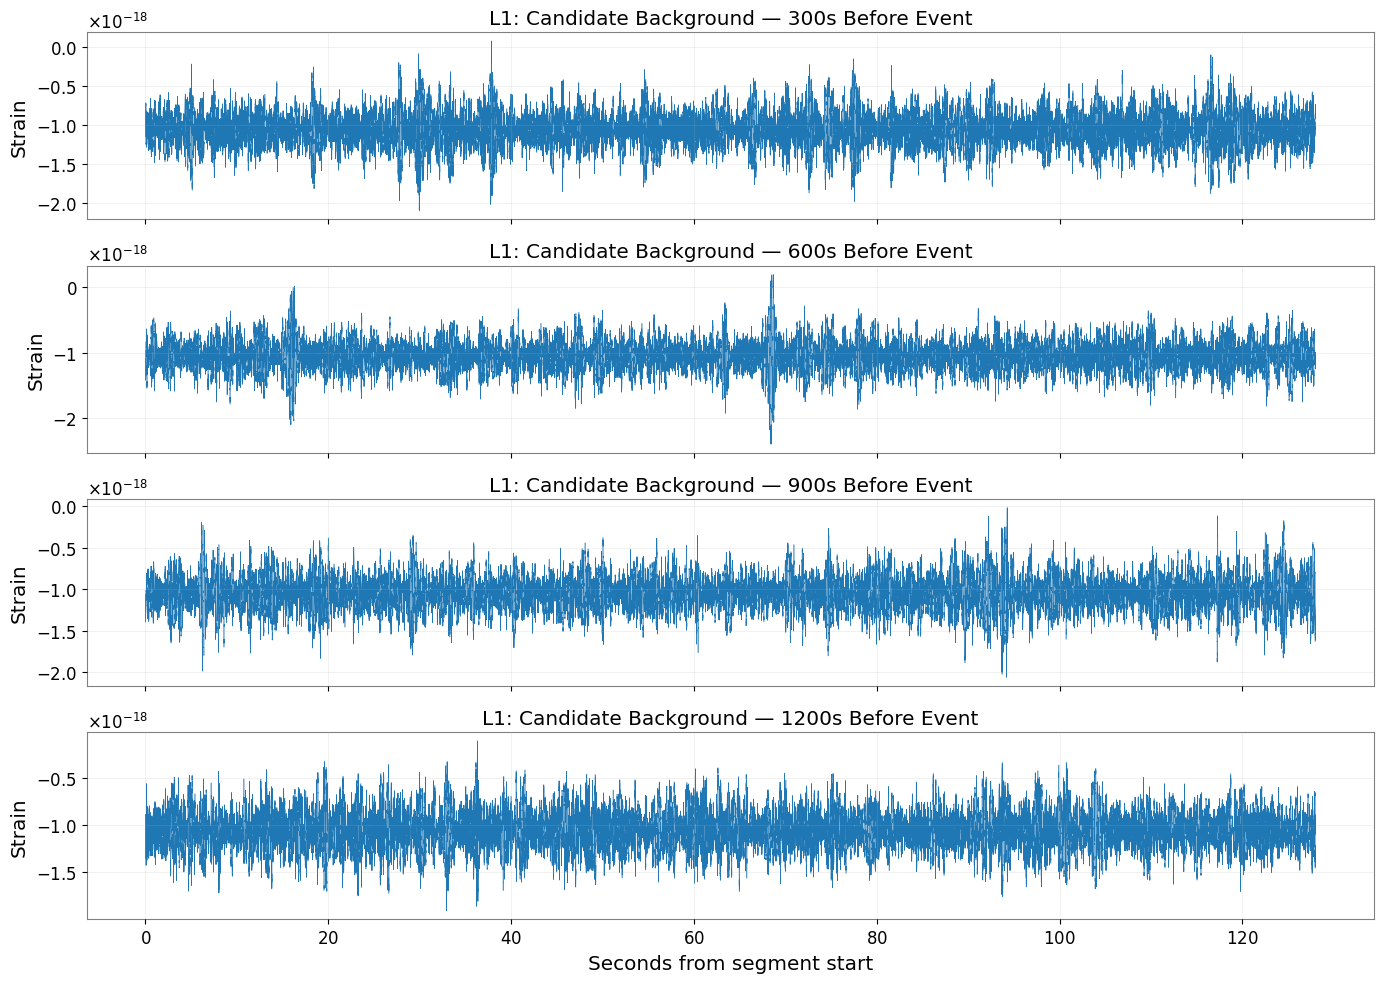

RAW-DATA SUMMARY

H1
event                    std=2.216e-19  99% |strain|=5.845e-19  range=[-7.045e-19, 7.706e-19]
background_offset_300s   std=2.117e-19  99% |strain|=5.761e-19  range=[-8.722e-19, 9.455e-19]
background_offset_600s   std=2.105e-19  99% |strain|=5.716e-19  range=[-1.071e-18, 1.063e-18]
background_offset_900s   std=2.027e-19  99% |strain|=5.306e-19  range=[-7.652e-19, 7.899e-19]
background_offset_1200s  std=2.115e-19  99% |strain|=5.767e-19  range=[-8.476e-19, 8.147e-19]

L1
event                    std=2.328e-19  99% |strain|=1.610e-18  range=[-1.870e-18, -4.600e-20]
background_offset_300s   std=2.250e-19  99% |strain|=1.622e-18  range=[-2.103e-18, 7.717e-20]
background_offset_600s   std=2.328e-19  99% |strain|=1.603e-18  range=[-2.404e-18, 1.998e-19]
background_offset_900s   std=2.167e-19  99% |strain|=1.567e-18  range=[-2.068e-18, -1.181e-20]
background_offset_1200s  std=2.072e-19  99% |strain|=1.533e-18  range=[-1.908e-18, -9.854e-20]

Saved inspection statistics to 

In [4]:

# PHASE 2A — Inspect raw event and background strain
# No filtering, whitening, or normalization is applied here.

import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_DIR = Path("/content/gw150914_flagship")
RAW_DIR = PROJECT_DIR / "raw"
REPORT_DIR = PROJECT_DIR / "reports"

FS = 4096
SEGMENT_DURATION = 128
OFFSETS = [300, 600, 900, 1200]

# Load the saved raw event data.
event = {
    "H1": np.load(RAW_DIR / "H1_GW150914_raw.npy"),
    "L1": np.load(RAW_DIR / "L1_GW150914_raw.npy"),
}

# Load candidate background data.
backgrounds = {}
for detector in ["H1", "L1"]:
    backgrounds[detector] = {}
    for offset in OFFSETS:
        filename = f"{detector}_background_offset_{offset}s.npy"
        backgrounds[detector][offset] = np.load(RAW_DIR / filename)

# Plot event data: 32 seconds.
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

event_t = np.arange(len(event["H1"])) / FS

for ax, detector in zip(axes, ["H1", "L1"]):
    ax.plot(event_t, event[detector], linewidth=0.45)
    ax.set_title(f"{detector}: GW150914 Event Segment — Raw Strain")
    ax.set_ylabel("Strain")
    ax.grid(alpha=0.25)

axes[-1].set_xlabel("Seconds from segment start")
plt.tight_layout()
plt.show()

# Plot each background segment.
for detector in ["H1", "L1"]:
    fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)

    for ax, offset in zip(axes, OFFSETS):
        values = backgrounds[detector][offset]
        time_axis = np.arange(len(values)) / FS

        ax.plot(time_axis, values, linewidth=0.35)
        ax.set_title(f"{detector}: Candidate Background — {offset}s Before Event")
        ax.set_ylabel("Strain")
        ax.grid(alpha=0.25)

    axes[-1].set_xlabel("Seconds from segment start")
    plt.tight_layout()
    plt.show()

# Record basic robust and non-robust statistics.
# These help flag segments for closer inspection; they do not certify quality.
report = {}

for detector in ["H1", "L1"]:
    report[detector] = {}

    for label, values in [
        ("event", event[detector]),
        *[
            (f"background_offset_{offset}s", backgrounds[detector][offset])
            for offset in OFFSETS
        ]
    ]:
        median = np.median(values)
        mad = np.median(np.abs(values - median))

        report[detector][label] = {
            "samples": int(len(values)),
            "mean": float(np.mean(values)),
            "standard_deviation": float(np.std(values)),
            "median": float(median),
            "median_absolute_deviation": float(mad),
            "minimum": float(np.min(values)),
            "maximum": float(np.max(values)),
            "percentile_99_abs": float(np.percentile(np.abs(values), 99)),
            "finite_values": bool(np.isfinite(values).all())
        }

print("RAW-DATA SUMMARY")
for detector, entries in report.items():
    print(f"\n{detector}")
    for label, stats in entries.items():
        print(
            f"{label:24s} "
            f"std={stats['standard_deviation']:.3e}  "
            f"99% |strain|={stats['percentile_99_abs']:.3e}  "
            f"range=[{stats['minimum']:.3e}, {stats['maximum']:.3e}]"
        )

with open(REPORT_DIR / "raw_data_inspection.json", "w") as f:
    json.dump(report, f, indent=2)

print("\nSaved inspection statistics to reports/raw_data_inspection.json")
print("Do not discard any segment based on standard deviation alone.")


SAVED L1
  samples: 131072
  min/max: -1.8697138664295834e-18 -4.600351113045829e-20
  mean: -1.0518986985481623e-18
  first 8: [-9.57782180e-19 -9.44008859e-19 -9.68975657e-19 -1.00720009e-18
 -1.02819738e-18 -1.00508109e-18 -9.81986942e-19 -9.68522746e-19]
  last 8: [-7.70999143e-19 -8.01422561e-19 -8.09524093e-19 -7.72193916e-19
 -7.23749311e-19 -7.18181209e-19 -7.29759972e-19 -7.35275811e-19]

FRESH L1 DOWNLOAD
  samples: 131072
  min/max: -1.8697138664295834e-18 -4.600351113045829e-20
  mean: -1.0518986985481623e-18
  first 8: [-9.57782180e-19 -9.44008859e-19 -9.68975657e-19 -1.00720009e-18
 -1.02819738e-18 -1.00508109e-18 -9.81986942e-19 -9.68522746e-19]
  last 8: [-7.70999143e-19 -8.01422561e-19 -8.09524093e-19 -7.72193916e-19
 -7.23749311e-19 -7.18181209e-19 -7.29759972e-19 -7.35275811e-19]

COMPARISON
  max absolute difference: 0.0
  correlation: 0.9999999999999998
  identical: True


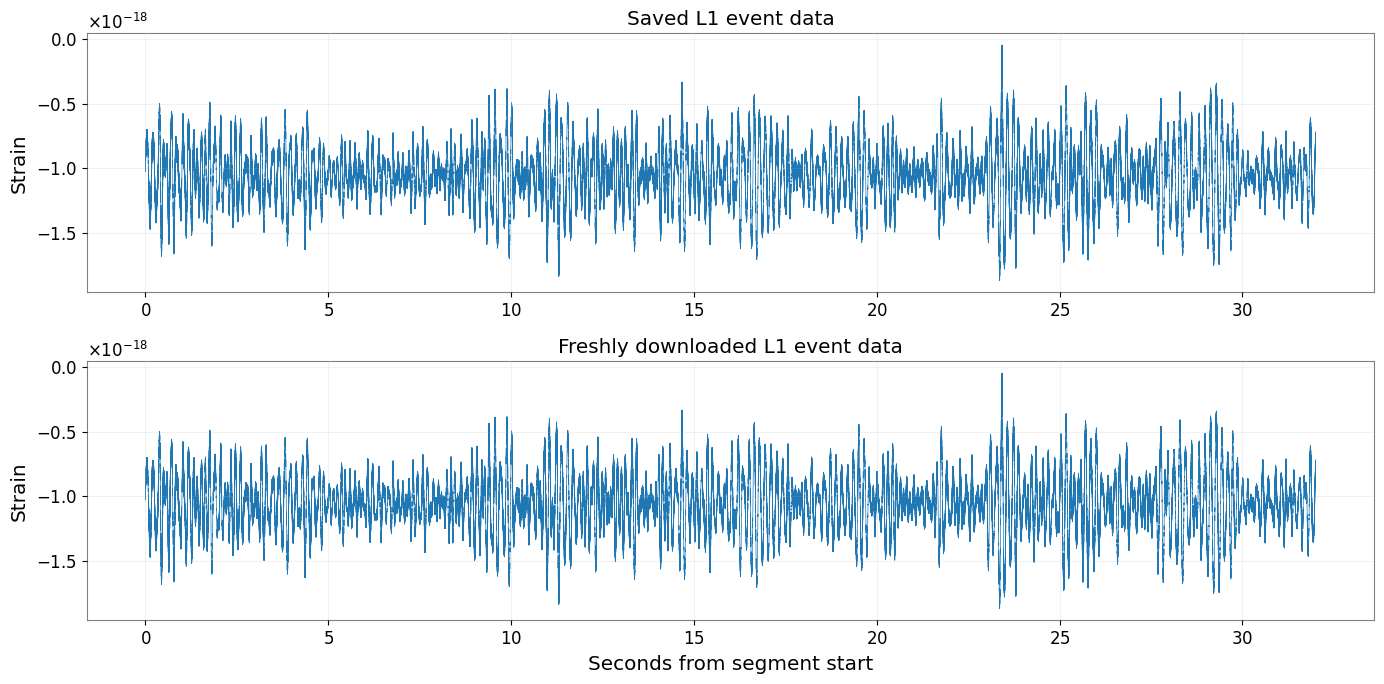

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from gwpy.timeseries import TimeSeries

PROJECT_DIR = Path("/content/gw150914_flagship")
RAW_DIR = PROJECT_DIR / "raw"

FS = 4096
EVENT_GPS = 1126259462.4
START_GPS = EVENT_GPS - 16
END_GPS = EVENT_GPS + 16

# Load saved data and independently fetch the same interval
saved = np.load(RAW_DIR / "L1_GW150914_raw.npy")

fresh_ts = TimeSeries.fetch_open_data(
    "L1",
    START_GPS,
    END_GPS,
    sample_rate=FS,
    cache=True
)
fresh = np.asarray(fresh_ts.value)

print("SAVED L1")
print("  samples:", len(saved))
print("  min/max:", np.min(saved), np.max(saved))
print("  mean:", np.mean(saved))
print("  first 8:", saved[:8])
print("  last 8:", saved[-8:])

print("\nFRESH L1 DOWNLOAD")
print("  samples:", len(fresh))
print("  min/max:", np.min(fresh), np.max(fresh))
print("  mean:", np.mean(fresh))
print("  first 8:", fresh[:8])
print("  last 8:", fresh[-8:])

if len(saved) == len(fresh):
    difference = saved - fresh
    print("\nCOMPARISON")
    print("  max absolute difference:", np.max(np.abs(difference)))
    print("  correlation:", np.corrcoef(saved, fresh)[0, 1])
    print("  identical:", np.array_equal(saved, fresh))
else:
    print("\nSample counts differ; compare timing before comparing values.")

fig, axes = plt.subplots(2, 1, figsize=(14, 7))

axes[0].plot(np.arange(len(saved)) / FS, saved, linewidth=0.5)
axes[0].set_title("Saved L1 event data")
axes[0].set_ylabel("Strain")
axes[0].grid(alpha=0.25)

axes[1].plot(np.arange(len(fresh)) / FS, fresh, linewidth=0.5)
axes[1].set_title("Freshly downloaded L1 event data")
axes[1].set_xlabel("Seconds from segment start")
axes[1].set_ylabel("Strain")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()


H1
Raw mean:          -3.735450e-22
Subtracted mean:   -9.403955e-38
Raw standard dev:  2.215893e-19
After subtraction: 2.215893e-19

L1
Raw mean:          -1.051899e-18
Subtracted mean:   -7.271608e-35
Raw standard dev:  2.327736e-19
After subtraction: 2.327736e-19


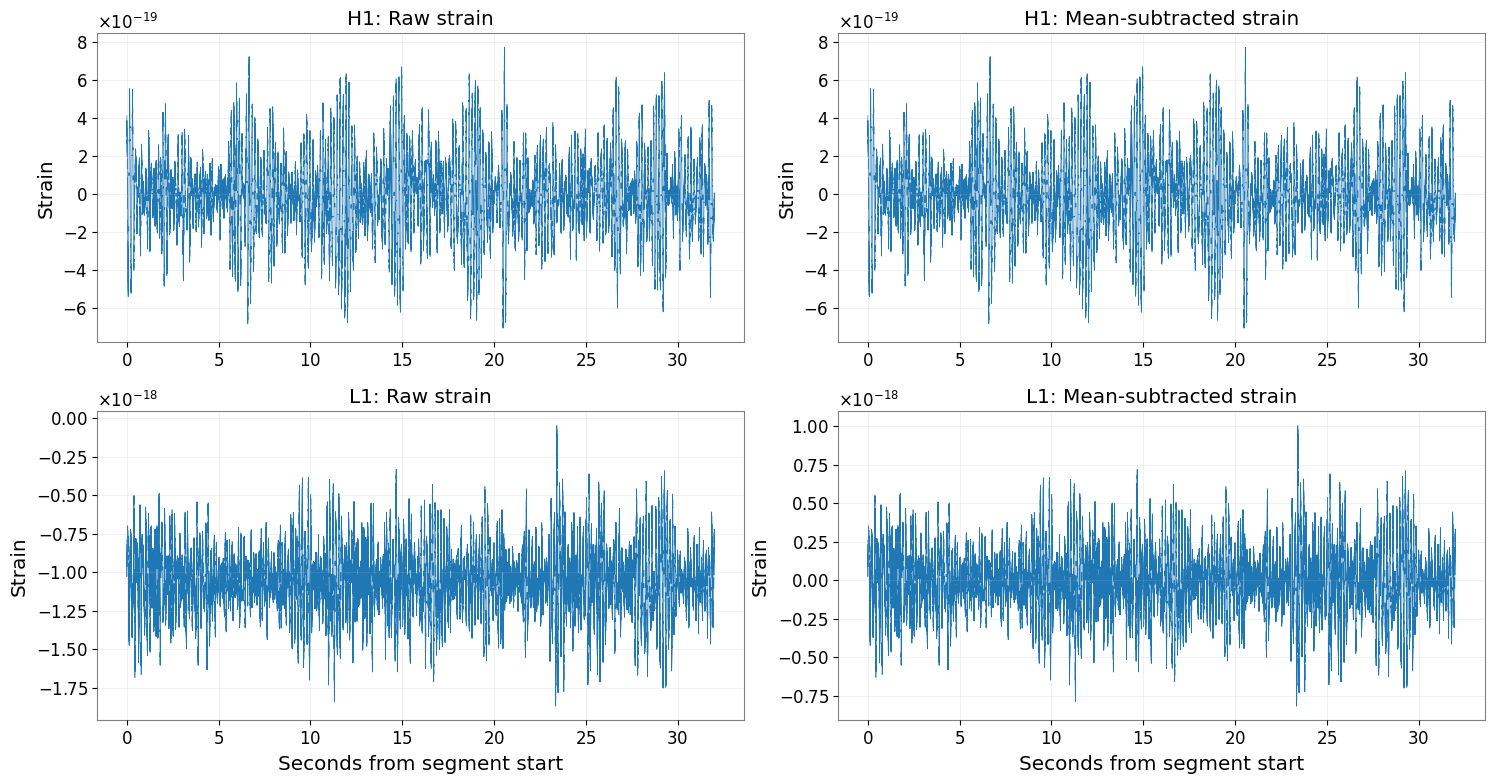

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

RAW_DIR = Path("/content/gw150914_flagship/raw")
FS = 4096

event = {
    "H1": np.load(RAW_DIR / "H1_GW150914_raw.npy"),
    "L1": np.load(RAW_DIR / "L1_GW150914_raw.npy"),
}

fig, axes = plt.subplots(2, 2, figsize=(15, 8))

for row, detector in enumerate(["H1", "L1"]):
    raw = event[detector]
    demeaned = raw - np.mean(raw)
    time = np.arange(len(raw)) / FS

    axes[row, 0].plot(time, raw, linewidth=0.45)
    axes[row, 0].set_title(f"{detector}: Raw strain")
    axes[row, 0].set_ylabel("Strain")
    axes[row, 0].grid(alpha=0.25)

    axes[row, 1].plot(time, demeaned, linewidth=0.45)
    axes[row, 1].set_title(f"{detector}: Mean-subtracted strain")
    axes[row, 1].set_ylabel("Strain")
    axes[row, 1].grid(alpha=0.25)

    print(f"\n{detector}")
    print(f"Raw mean:          {np.mean(raw):.6e}")
    print(f"Subtracted mean:   {np.mean(demeaned):.6e}")
    print(f"Raw standard dev:  {np.std(raw):.6e}")
    print(f"After subtraction: {np.std(demeaned):.6e}")

axes[1, 0].set_xlabel("Seconds from segment start")
axes[1, 1].set_xlabel("Seconds from segment start")

plt.tight_layout()
plt.show()

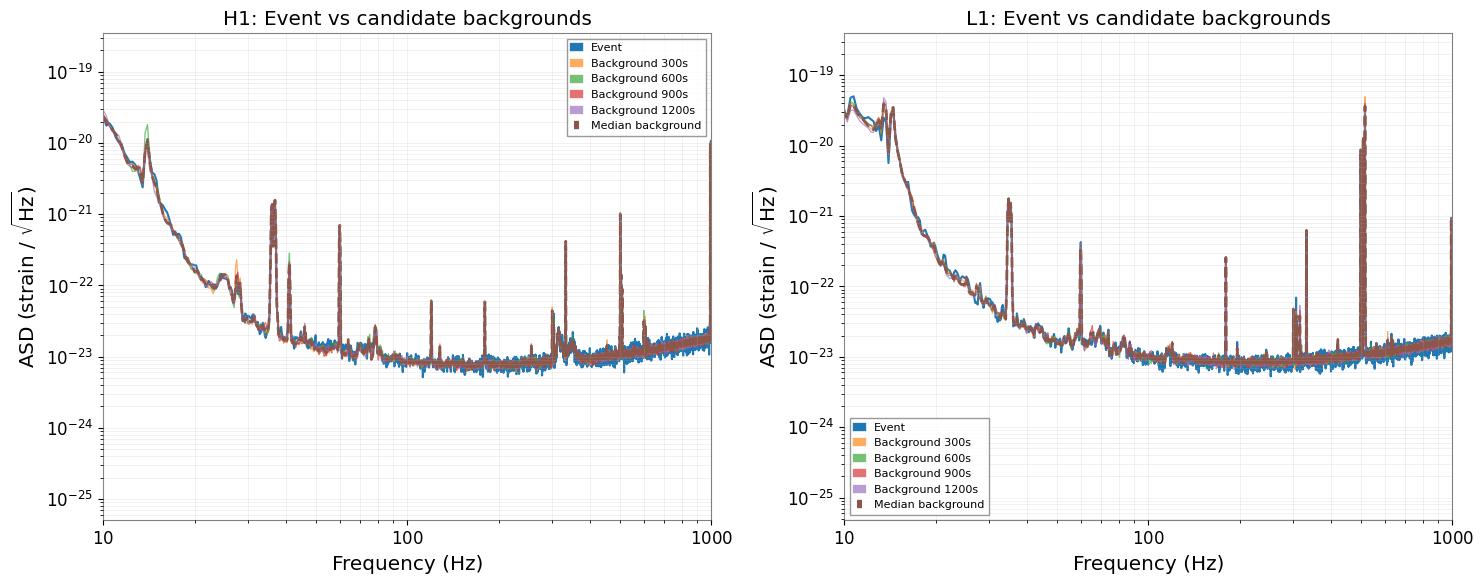

ASD ANALYSIS — INTEGRATED 20–300 Hz NOISE

H1
event               : 1.4832e-21 strain
background_300s     : 1.4783e-21 strain
background_600s     : 1.4857e-21 strain
background_900s     : 1.4858e-21 strain
background_1200s    : 1.4820e-21 strain

L1
event               : 1.5913e-21 strain
background_300s     : 1.5650e-21 strain
background_600s     : 1.5684e-21 strain
background_900s     : 1.5673e-21 strain
background_1200s    : 1.5673e-21 strain

Saved plot: /content/gw150914_flagship/figures/phase3A_asd_comparison.png
Saved spectrum report: /content/gw150914_flagship/reports/asd_comparison.json


In [7]:
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.signal import welch

PROJECT_DIR = Path("/content/gw150914_flagship")
RAW_DIR = PROJECT_DIR / "raw"
PROCESSED_DIR = PROJECT_DIR / "processed"
FIGURES_DIR = PROJECT_DIR / "figures"
REPORT_DIR = PROJECT_DIR / "reports"

for folder in [PROCESSED_DIR, FIGURES_DIR, REPORT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

FS = 4096
OFFSETS = [300, 600, 900, 1200]

# Four-second Welch windows with 50% overlap
NPERSEG = 4 * FS
NOVERLAP = NPERSEG // 2

data = {}
for detector in ["H1", "L1"]:
    data[detector] = {
        "event": np.load(RAW_DIR / f"{detector}_GW150914_raw.npy")
    }
    for offset in OFFSETS:
        label = f"background_{offset}s"
        filename = f"{detector}_background_offset_{offset}s.npy"
        data[detector][label] = np.load(RAW_DIR / filename)

results = {}

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, detector in zip(axes, ["H1", "L1"]):
    results[detector] = {}
    background_asds = []

    for label, strain in data[detector].items():
        if not np.isfinite(strain).all():
            raise ValueError(f"{detector} {label} contains non-finite values.")

        frequencies, psd = welch(
            strain,
            fs=FS,
            window="hann",
            nperseg=NPERSEG,
            noverlap=NOVERLAP,
            detrend="constant",
            scaling="density"
        )

        asd = np.sqrt(np.maximum(psd, 0))
        results[detector][label] = {
            "frequencies_hz": frequencies.tolist(),
            "asd_strain_per_sqrt_hz": asd.tolist()
        }

        if label == "event":
            ax.loglog(frequencies[1:], asd[1:],
                      label="Event", linewidth=1.5)
        else:
            background_asds.append(asd)
            ax.loglog(frequencies[1:], asd[1:],
                      alpha=0.65, linewidth=0.9,
                      label=label.replace("background_", "Background "))

    # Add the median of the four candidate-background ASD curves.
    median_background_asd = np.median(np.vstack(background_asds), axis=0)
    ax.loglog(
        frequencies[1:],
        median_background_asd[1:],
        linestyle="--",
        linewidth=2,
        label="Median background"
    )

    ax.set_xlim(10, 1000)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel(r"ASD (strain / $\sqrt{\mathrm{Hz}}$)")
    ax.set_title(f"{detector}: Event vs candidate backgrounds")
    ax.grid(True, which="both", alpha=0.25)
    ax.legend(fontsize=8)

plt.tight_layout()
figure_path = FIGURES_DIR / "phase3A_asd_comparison.png"
plt.savefig(figure_path, dpi=160, bbox_inches="tight")
plt.show()

# Save numerical results for reproducibility.
output_path = REPORT_DIR / "asd_comparison.json"
with open(output_path, "w") as f:
    json.dump(results, f)

# Compare integrated noise over 20–300 Hz.
print("ASD ANALYSIS — INTEGRATED 20–300 Hz NOISE")
for detector in ["H1", "L1"]:
    print(f"\n{detector}")
    for label, strain in data[detector].items():
        f, psd = welch(
            strain,
            fs=FS,
            window="hann",
            nperseg=NPERSEG,
            noverlap=NOVERLAP,
            detrend="constant",
            scaling="density"
        )
        band = (f >= 20) & (f <= 300)
        band_rms = np.sqrt(np.trapezoid(psd[band], f[band]))
        print(f"{label:20s}: {band_rms:.4e} strain")

print(f"\nSaved plot: {figure_path}")
print(f"Saved spectrum report: {output_path}")

In [8]:
import json
import math
from pathlib import Path
from gwosc.timeline import get_segments

PROJECT_DIR = Path("/content/gw150914_flagship")
REPORT_DIR = PROJECT_DIR / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

EVENT_GPS = 1126259462.4
OFFSETS = [300, 600, 900, 1200]

# Intervals correspond to the data already downloaded.
intervals = {
    "GW150914_event": (
        EVENT_GPS - 16,
        EVENT_GPS + 16
    )
}

for offset in OFFSETS:
    center = EVENT_GPS - offset
    intervals[f"background_offset_{offset}s"] = (
        center - 64,
        center + 64
    )

def fully_covered(start, end, segments):
    """Check whether the union of official segments covers [start, end)."""
    cursor = start

    for seg_start, seg_end in sorted(segments):
        if seg_end <= cursor:
            continue
        if seg_start > cursor:
            return False
        cursor = max(cursor, seg_end)
        if cursor >= end:
            return True

    return cursor >= end

report = {}

for detector in ["H1", "L1"]:
    print(f"\n{detector}: querying official DATA segments")

    query_start = math.floor(min(s for s, e in intervals.values()))
    query_end = math.ceil(max(e for s, e in intervals.values()))

    try:
        segments = get_segments(
            f"{detector}_DATA",
            query_start,
            query_end
        )

        detector_results = {}

        for name, (start, end) in intervals.items():
            # DQ segments are represented at whole-second resolution.
            check_start = math.floor(start)
            check_end = math.ceil(end)

            covered = fully_covered(
                check_start,
                check_end,
                segments
            )

            detector_results[name] = {
                "start_gps": start,
                "end_gps": end,
                "integer_second_interval_fully_covered": covered
            }

            print(
                f"{name:24s} "
                f"GPS [{start:.1f}, {end:.1f}) "
                f"fully covered: {covered}"
            )

        report[detector] = detector_results

    except Exception as exc:
        print(
            f"Could not retrieve or interpret {detector} DATA flags: "
            f"{type(exc).__name__}: {exc}"
        )
        report[detector] = {
            "query_error": f"{type(exc).__name__}: {exc}"
        }

output_path = REPORT_DIR / "official_data_flag_check.json"

with open(output_path, "w") as f:
    json.dump(report, f, indent=2)

print(f"\nSaved report: {output_path}")


H1: querying official DATA segments
GW150914_event           GPS [1126259446.4, 1126259478.4) fully covered: True
background_offset_300s   GPS [1126259098.4, 1126259226.4) fully covered: True
background_offset_600s   GPS [1126258798.4, 1126258926.4) fully covered: True
background_offset_900s   GPS [1126258498.4, 1126258626.4) fully covered: True
background_offset_1200s  GPS [1126258198.4, 1126258326.4) fully covered: True

L1: querying official DATA segments
GW150914_event           GPS [1126259446.4, 1126259478.4) fully covered: True
background_offset_300s   GPS [1126259098.4, 1126259226.4) fully covered: True
background_offset_600s   GPS [1126258798.4, 1126258926.4) fully covered: True
background_offset_900s   GPS [1126258498.4, 1126258626.4) fully covered: True
background_offset_1200s  GPS [1126258198.4, 1126258326.4) fully covered: True

Saved report: /content/gw150914_flagship/reports/official_data_flag_check.json


## Apply a controlled bandpass filter


H1
  Raw standard deviation:      2.215893e-19
  Filtered standard deviation: 1.717305e-21
  Filtered minimum:            -5.625682e-20
  Filtered maximum:            1.598197e-20

L1
  Raw standard deviation:      2.327736e-19
  Filtered standard deviation: 1.391127e-20
  Filtered minimum:            -6.088566e-20
  Filtered maximum:            4.858262e-20


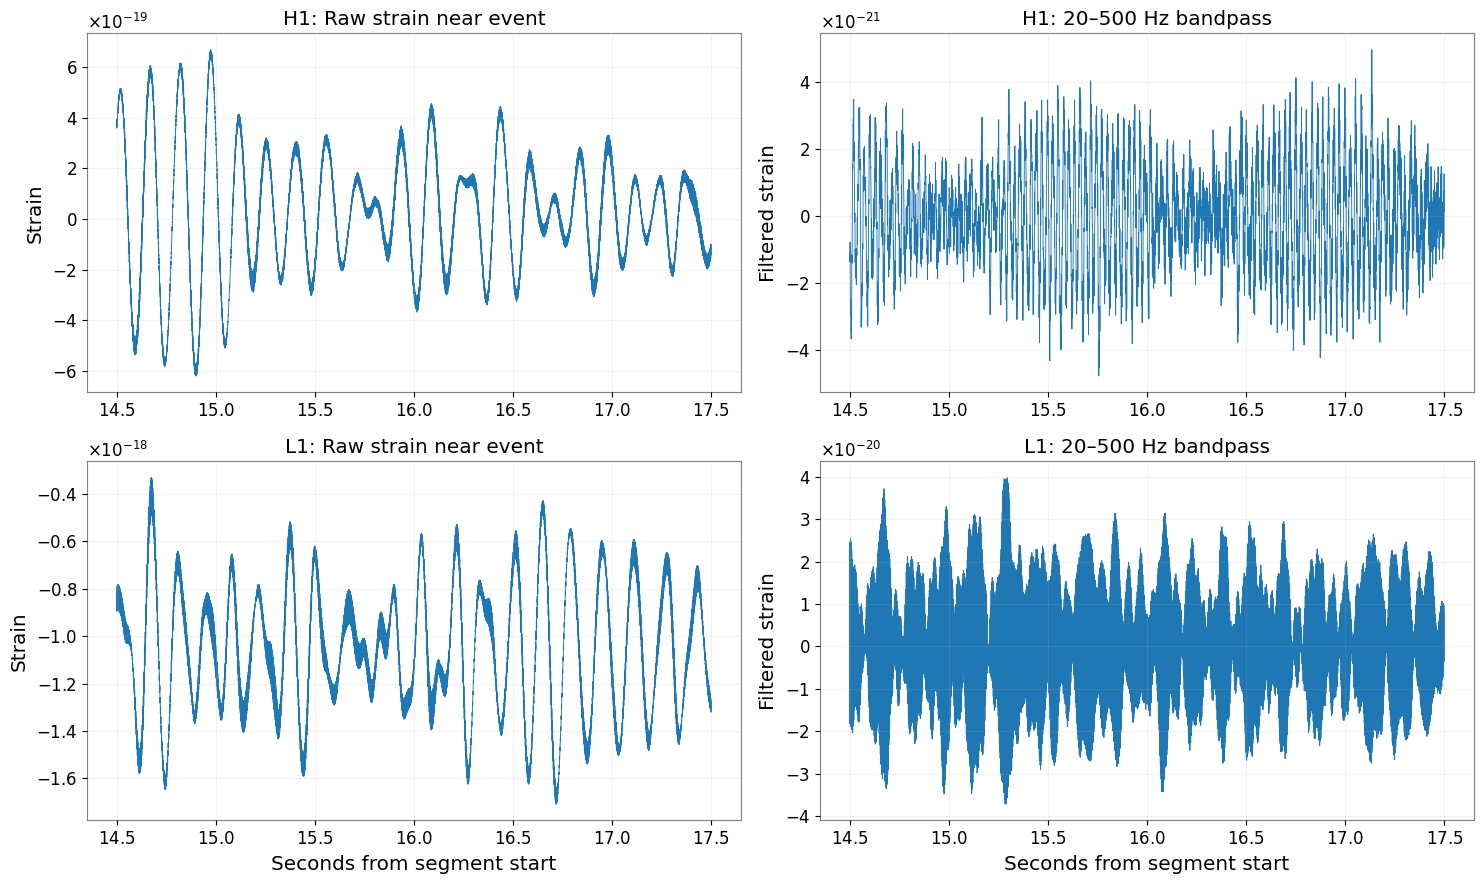

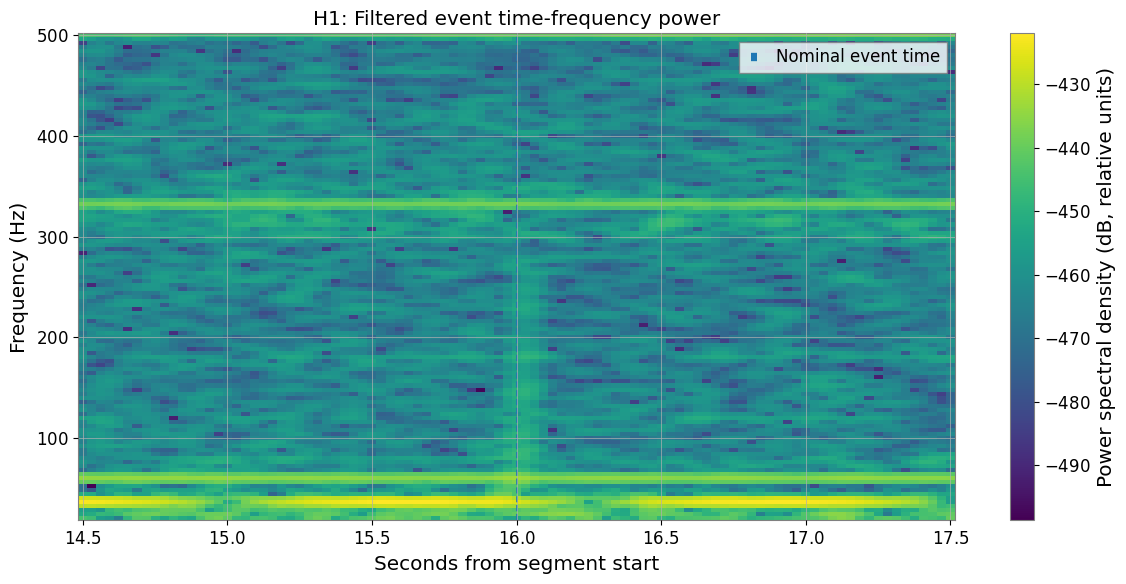


Saved filtered arrays to: /content/gw150914_flagship/processed
Saved figures to: /content/gw150914_flagship/figures


In [9]:
import json
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.signal import butter, sosfiltfilt, spectrogram

PROJECT_DIR = Path("/content/gw150914_flagship")
RAW_DIR = PROJECT_DIR / "raw"
PROCESSED_DIR = PROJECT_DIR / "processed"
FIGURES_DIR = PROJECT_DIR / "figures"
REPORT_DIR = PROJECT_DIR / "reports"

for folder in [PROCESSED_DIR, FIGURES_DIR, REPORT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

FS = 4096
EVENT_GPS = 1126259462.4
EVENT_TIME_IN_SEGMENT = 16.0
LOW_HZ = 20.0
HIGH_HZ = 500.0
FILTER_ORDER = 4

# Design a numerically stable Butterworth bandpass.
sos = butter(
    FILTER_ORDER,
    [LOW_HZ, HIGH_HZ],
    btype="bandpass",
    fs=FS,
    output="sos"
)

raw_event = {}
filtered_event = {}

for detector in ["H1", "L1"]:
    raw = np.load(RAW_DIR / f"{detector}_GW150914_raw.npy")

    if not np.isfinite(raw).all():
        raise ValueError(f"{detector} event data contains non-finite values.")

    # Remove the constant mean for processing, without altering raw files.
    centered = raw - np.mean(raw)

    # Forward-backward filtering avoids a net phase shift.
    filtered = sosfiltfilt(sos, centered)

    raw_event[detector] = raw
    filtered_event[detector] = filtered

    np.save(
        PROCESSED_DIR / f"{detector}_GW150914_bandpass_20_500Hz.npy",
        filtered
    )

    print(f"\n{detector}")
    print(f"  Raw standard deviation:      {np.std(raw):.6e}")
    print(f"  Filtered standard deviation: {np.std(filtered):.6e}")
    print(f"  Filtered minimum:            {np.min(filtered):.6e}")
    print(f"  Filtered maximum:            {np.max(filtered):.6e}")

# Plot the event-centered region; avoid interpreting filter-edge regions.
time = np.arange(len(raw_event["H1"])) / FS
zoom = (time >= EVENT_TIME_IN_SEGMENT - 1.5) & (
    time <= EVENT_TIME_IN_SEGMENT + 1.5
)

fig, axes = plt.subplots(2, 2, figsize=(15, 9))

for row, detector in enumerate(["H1", "L1"]):
    axes[row, 0].plot(
        time[zoom], raw_event[detector][zoom], linewidth=0.65
    )
    axes[row, 0].set_title(f"{detector}: Raw strain near event")
    axes[row, 0].set_ylabel("Strain")
    axes[row, 0].grid(alpha=0.25)

    axes[row, 1].plot(
        time[zoom], filtered_event[detector][zoom], linewidth=0.65
    )
    axes[row, 1].set_title(f"{detector}: 20–500 Hz bandpass")
    axes[row, 1].set_ylabel("Filtered strain")
    axes[row, 1].grid(alpha=0.25)

axes[1, 0].set_xlabel("Seconds from segment start")
axes[1, 1].set_xlabel("Seconds from segment start")

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "phase4A_raw_vs_bandpass.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

# Inspect time-frequency structure in the filtered H1 event data.
frequencies, times, power = spectrogram(
    filtered_event["H1"],
    fs=FS,
    window="hann",
    nperseg=1024,
    noverlap=896,
    detrend="constant",
    scaling="density",
    mode="psd"
)

time_mask = (
    (times >= EVENT_TIME_IN_SEGMENT - 1.5)
    & (times <= EVENT_TIME_IN_SEGMENT + 1.5)
)
freq_mask = (frequencies >= 20) & (frequencies <= 500)

fig, ax = plt.subplots(figsize=(12, 6))
mesh = ax.pcolormesh(
    times[time_mask],
    frequencies[freq_mask],
    10 * np.log10(power[np.ix_(freq_mask, time_mask)] + 1e-60),
    shading="auto"
)
ax.axvline(
    EVENT_TIME_IN_SEGMENT,
    linestyle="--",
    linewidth=1.2,
    label="Nominal event time"
)
ax.set_xlabel("Seconds from segment start")
ax.set_ylabel("Frequency (Hz)")
ax.set_title("H1: Filtered event time-frequency power")
ax.legend()
fig.colorbar(mesh, ax=ax, label="Power spectral density (dB, relative units)")
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "phase4A_H1_spectrogram.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

print("\nSaved filtered arrays to:", PROCESSED_DIR)
print("Saved figures to:", FIGURES_DIR)

Brighter colors: higher estimated power.



Darker colors: lower estimated power.



Horizontal lines: persistent frequencies or narrowband features.

## a clearer gravitational-wave spectrogram

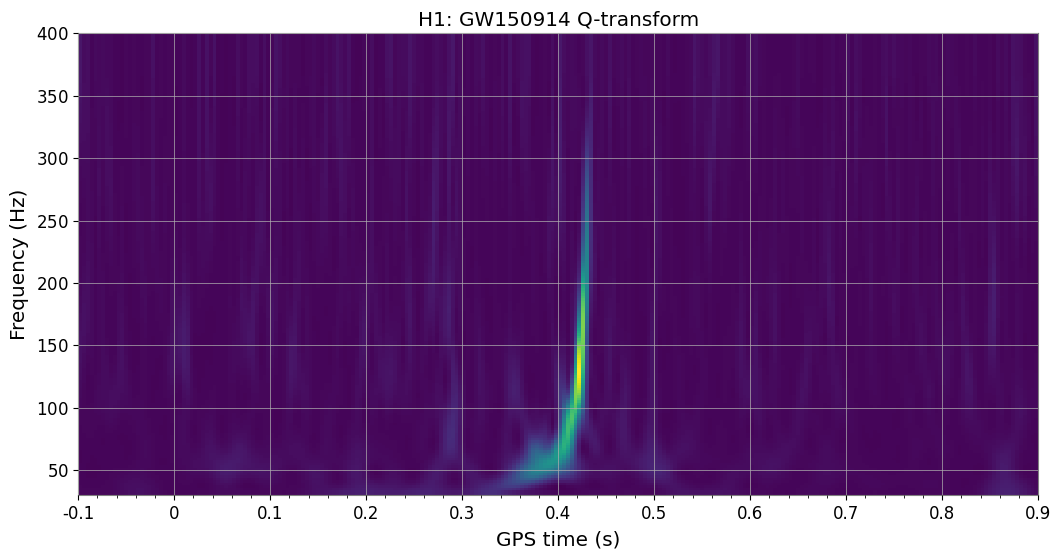

Saved: /content/gw150914_flagship/figures/phase4B_H1_qtransform.png


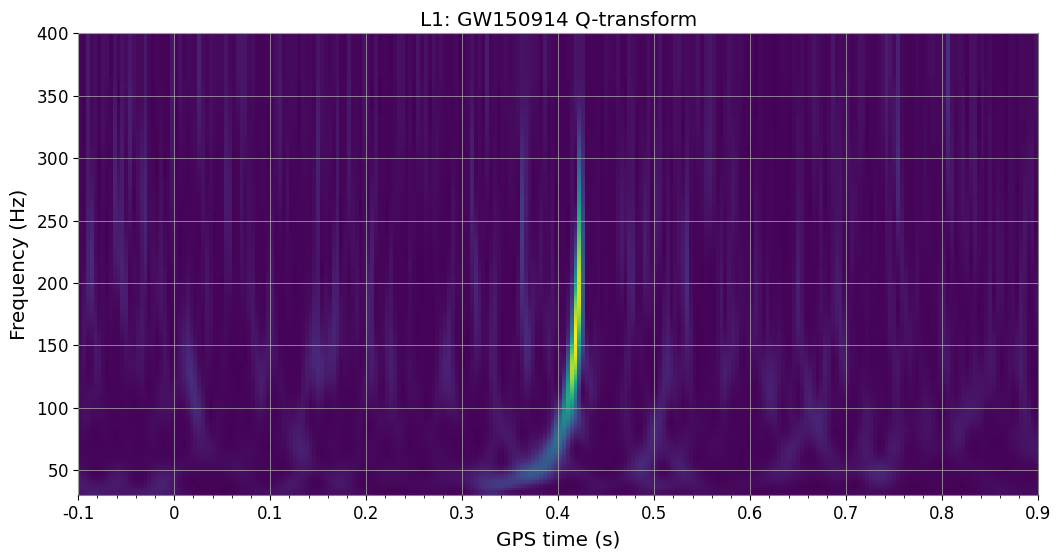

Saved: /content/gw150914_flagship/figures/phase4B_L1_qtransform.png
Q-transform step finished.


In [10]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from gwpy.timeseries import TimeSeries

PROJECT_DIR = Path("/content/gw150914_flagship")
RAW_DIR = PROJECT_DIR / "raw"
FIGURES_DIR = PROJECT_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

FS = 4096
EVENT_GPS = 1126259462.4

for detector in ["H1", "L1"]:
    raw = np.load(RAW_DIR / f"{detector}_GW150914_raw.npy")

    strain = TimeSeries(
        raw,
        t0=EVENT_GPS - 16,
        dt=1 / FS,
        channel=f"{detector}:GWOSC-STRAIN"
    )

    # Give the Q-transform more data around the event.
    centered = strain.crop(
        EVENT_GPS - 2,
        EVENT_GPS + 2
    )

    # Transform the longer segment, then display the event-centered region.
    qspec = centered.q_transform(
        frange=(30, 400),
        qrange=(4, 32),
        tres=0.004,
        fres=2
    )

    fig = qspec.plot()
    ax = fig.gca()
    ax.set_xlim(EVENT_GPS - 0.5, EVENT_GPS + 0.5)
    ax.set_ylim(30, 400)
    ax.set_title(f"{detector}: GW150914 Q-transform")
    ax.set_xlabel("GPS time (s)")
    ax.set_ylabel("Frequency (Hz)")

    output = FIGURES_DIR / f"phase4B_{detector}_qtransform.png"
    fig.savefig(output, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print("Saved:", output)

print("Q-transform step finished.")


## check the event-centered timing

In [11]:
import numpy as np
from pathlib import Path

PROJECT_DIR = Path("/content/gw150914_flagship")
EVENT_GPS = 1126259462.4

for detector in ["H1", "L1"]:
    path = PROJECT_DIR / "processed" / f"{detector}_GW150914_bandpass_20_500Hz.npy"
    data = np.load(path)

    t = np.arange(len(data)) / 4096 - 16
    event_window = (t >= -0.5) & (t <= 0.5)

    local_t = t[event_window]
    local_data = data[event_window]

    peak_idx = np.argmax(np.abs(local_data))

    print(f"\n{detector}")
    print(f"Largest absolute filtered peak: {local_t[peak_idx]:+.4f} s relative to event")
    print(f"GPS time: {EVENT_GPS + local_t[peak_idx]:.4f}")
    print(f"Peak amplitude: {local_data[peak_idx]:.4e}")


H1
Largest absolute filtered peak: -0.2437 s relative to event
GPS time: 1126259462.1563
Peak amplitude: -4.7909e-21

L1
Largest absolute filtered peak: +0.0806 s relative to event
GPS time: 1126259462.4806
Peak amplitude: -3.4196e-20


## inspect the waveform around the merger

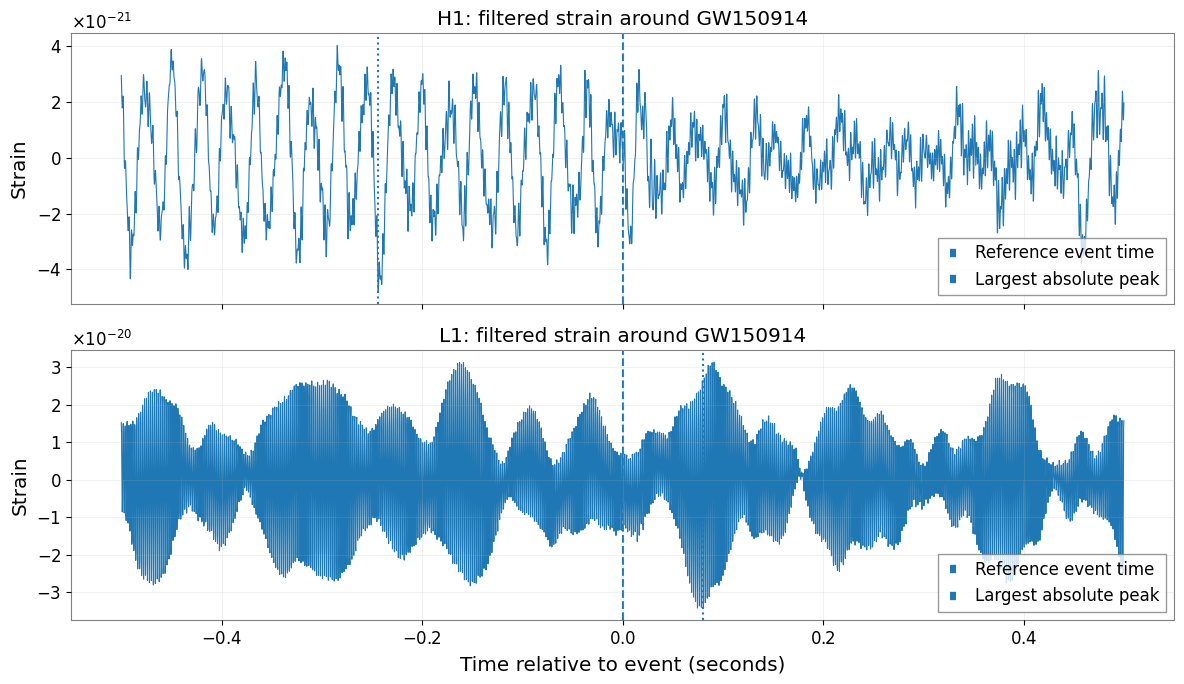

Saved: /content/gw150914_flagship/figures/phase4C_event_waveforms.png


In [12]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_DIR = Path("/content/gw150914_flagship")
FIGURES_DIR = PROJECT_DIR / "figures"

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

for ax, detector in zip(axes, ["H1", "L1"]):
    path = (
        PROJECT_DIR / "processed" /
        f"{detector}_GW150914_bandpass_20_500Hz.npy"
    )
    data = np.load(path)

    t = np.arange(len(data)) / 4096 - 16
    mask = (t >= -0.5) & (t <= 0.5)

    ax.plot(t[mask], data[mask], linewidth=0.8)
    ax.axvline(0, linestyle="--", label="Reference event time")
    ax.axvline(-0.2437 if detector == "H1" else 0.0806,
               linestyle=":", label="Largest absolute peak")
    ax.set_title(f"{detector}: filtered strain around GW150914")
    ax.set_ylabel("Strain")
    ax.grid(True, alpha=0.25)
    ax.legend()

axes[-1].set_xlabel("Time relative to event (seconds)")
plt.tight_layout()

output = FIGURES_DIR / "phase4C_event_waveforms.png"
plt.savefig(output, dpi=160, bbox_inches="tight")
plt.show()
print("Saved:", output)


## Whiten H1 and L1


Processing H1...
Saved: /content/gw150914_flagship/processed/H1_GW150914_whitened.npy
Samples: 98304
Duration (s): 24.0
Whitened mean: -6.716909794689817e-05
Whitened standard deviation: 0.997765497982158


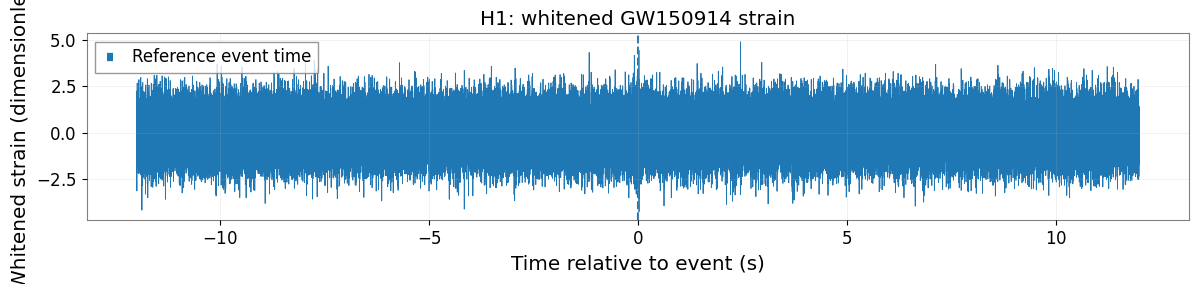


Processing L1...
Saved: /content/gw150914_flagship/processed/L1_GW150914_whitened.npy
Samples: 98304
Duration (s): 24.0
Whitened mean: 2.013509048540608e-05
Whitened standard deviation: 0.9846363064719202


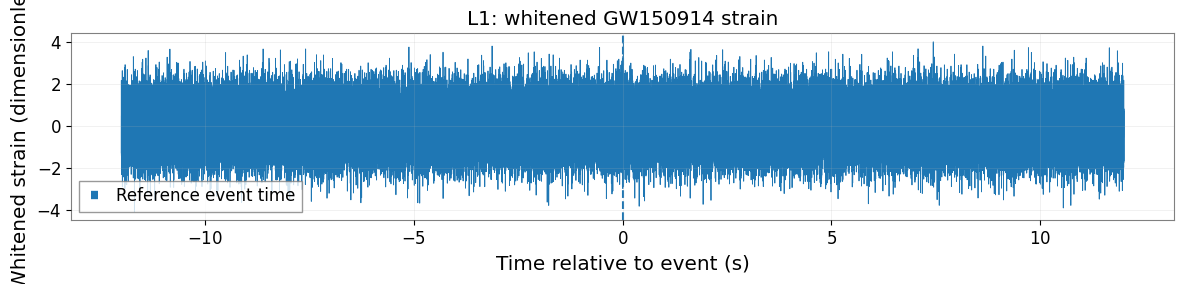


Phase 5A complete.


In [13]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from gwpy.timeseries import TimeSeries
from gwpy.frequencyseries import FrequencySeries

PROJECT_DIR = Path("/content/gw150914_flagship")
RAW_DIR = PROJECT_DIR / "raw"
PROCESSED_DIR = PROJECT_DIR / "processed"
FIGURES_DIR = PROJECT_DIR / "figures"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

FS = 4096
EVENT_GPS = 1126259462.4
OFFSETS = [300, 600, 900, 1200]

whitened = {}

for detector in ["H1", "L1"]:
    print(f"\nProcessing {detector}...")

    # Load the original event data.
    event_raw = np.load(
        RAW_DIR / f"{detector}_GW150914_raw.npy"
    )

    event_ts = TimeSeries(
        event_raw,
        t0=EVENT_GPS - 16,
        dt=1 / FS
    )

    # Estimate the noise ASD independently from off-source segments.
    asd_estimates = []

    for offset in OFFSETS:
        bg_path = (
            RAW_DIR /
            f"{detector}_background_offset_{offset}s.npy"
        )
        bg = np.load(bg_path)

        bg_ts = TimeSeries(bg, t0=0, dt=1 / FS)

        asd = bg_ts.asd(
            fftlength=4,
            overlap=2,
            method="median"
        )
        asd_estimates.append(asd)

    # Median across the four candidate background ASDs.
    median_asd_values = np.median(
        np.stack([np.asarray(a.value) for a in asd_estimates]),
        axis=0
    )

    median_asd = FrequencySeries(
        median_asd_values,
        f0=asd_estimates[0].f0,
        df=asd_estimates[0].df,
        unit=asd_estimates[0].unit
    )

    # Whiten using the background-derived ASD.
    white_ts = event_ts.whiten(
        asd=median_asd,
        fduration=4,
        highpass=20
    )

    # Save only the central 24 seconds to reduce filter-edge effects.
    central = white_ts.crop(
        EVENT_GPS - 12,
        EVENT_GPS + 12
    )

    white_data = np.asarray(central.value)
    out_path = (
        PROCESSED_DIR /
        f"{detector}_GW150914_whitened.npy"
    )
    np.save(out_path, white_data)
    whitened[detector] = white_data

    print("Saved:", out_path)
    print("Samples:", len(white_data))
    print("Duration (s):", len(white_data) / FS)
    print("Whitened mean:", float(np.mean(white_data)))
    print("Whitened standard deviation:", float(np.std(white_data)))

    # Plot the whitened central event interval.
    t = np.asarray(central.times.value) - EVENT_GPS

    plt.figure(figsize=(12, 3))
    plt.plot(t, white_data, linewidth=0.6)
    plt.axvline(0, linestyle="--", label="Reference event time")
    plt.title(f"{detector}: whitened GW150914 strain")
    plt.xlabel("Time relative to event (s)")
    plt.ylabel("Whitened strain (dimensionless)")
    plt.grid(alpha=0.25)
    plt.legend()
    plt.tight_layout()

    fig_path = FIGURES_DIR / f"phase5A_{detector}_whitened.png"
    plt.savefig(fig_path, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()

print("\nPhase 5A complete.")


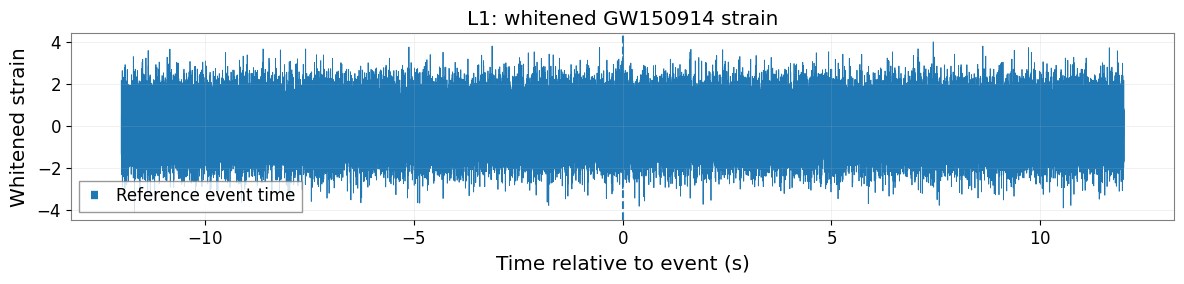

Saved: /content/gw150914_flagship/processed/L1_GW150914_whitened.npy
H1: samples=98304, duration=24.00s, mean=-6.71691e-05, std=0.997765, finite=True
L1: samples=98304, duration=24.00s, mean=2.01351e-05, std=0.984636, finite=True


In [14]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from gwpy.timeseries import TimeSeries
from gwpy.frequencyseries import FrequencySeries

PROJECT_DIR = Path("/content/gw150914_flagship")
RAW_DIR = PROJECT_DIR / "raw"
PROCESSED_DIR = PROJECT_DIR / "processed"
FIGURES_DIR = PROJECT_DIR / "figures"

FS = 4096
EVENT_GPS = 1126259462.4
OFFSETS = [300, 600, 900, 1200]

# Process L1; H1 is already saved.
detector = "L1"
raw = np.load(RAW_DIR / f"{detector}_GW150914_raw.npy")
event_ts = TimeSeries(raw, t0=EVENT_GPS - 16, dt=1 / FS)

asd_estimates = []
for offset in OFFSETS:
    bg = np.load(
        RAW_DIR / f"{detector}_background_offset_{offset}s.npy"
    )
    bg_ts = TimeSeries(bg, t0=0, dt=1 / FS)
    asd_estimates.append(
        bg_ts.asd(fftlength=4, overlap=2, method="median")
    )

median_values = np.median(
    np.stack([np.asarray(a.value) for a in asd_estimates]),
    axis=0
)
median_asd = FrequencySeries(
    median_values,
    f0=asd_estimates[0].f0,
    df=asd_estimates[0].df,
    unit=asd_estimates[0].unit
)

white_ts = event_ts.whiten(
    asd=median_asd,
    fduration=4,
    highpass=20
)
central = white_ts.crop(EVENT_GPS - 12, EVENT_GPS + 12)
white_data = np.asarray(central.value)

out_path = PROCESSED_DIR / "L1_GW150914_whitened.npy"
np.save(out_path, white_data)

t = np.asarray(central.times.value) - EVENT_GPS
plt.figure(figsize=(12, 3))
plt.plot(t, white_data, linewidth=0.6)
plt.axvline(0, linestyle="--", label="Reference event time")
plt.title("L1: whitened GW150914 strain")
plt.xlabel("Time relative to event (s)")
plt.ylabel("Whitened strain")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "phase5A_L1_whitened.png",
            dpi=160, bbox_inches="tight")
plt.show()

print("Saved:", out_path)

# Verify both detector arrays.
for det in ["H1", "L1"]:
    p = PROCESSED_DIR / f"{det}_GW150914_whitened.npy"
    x = np.load(p)
    print(
        f"{det}: samples={len(x)}, duration={len(x)/FS:.2f}s, "
        f"mean={np.mean(x):.6g}, std={np.std(x):.6g}, "
        f"finite={np.isfinite(x).all()}"
    )


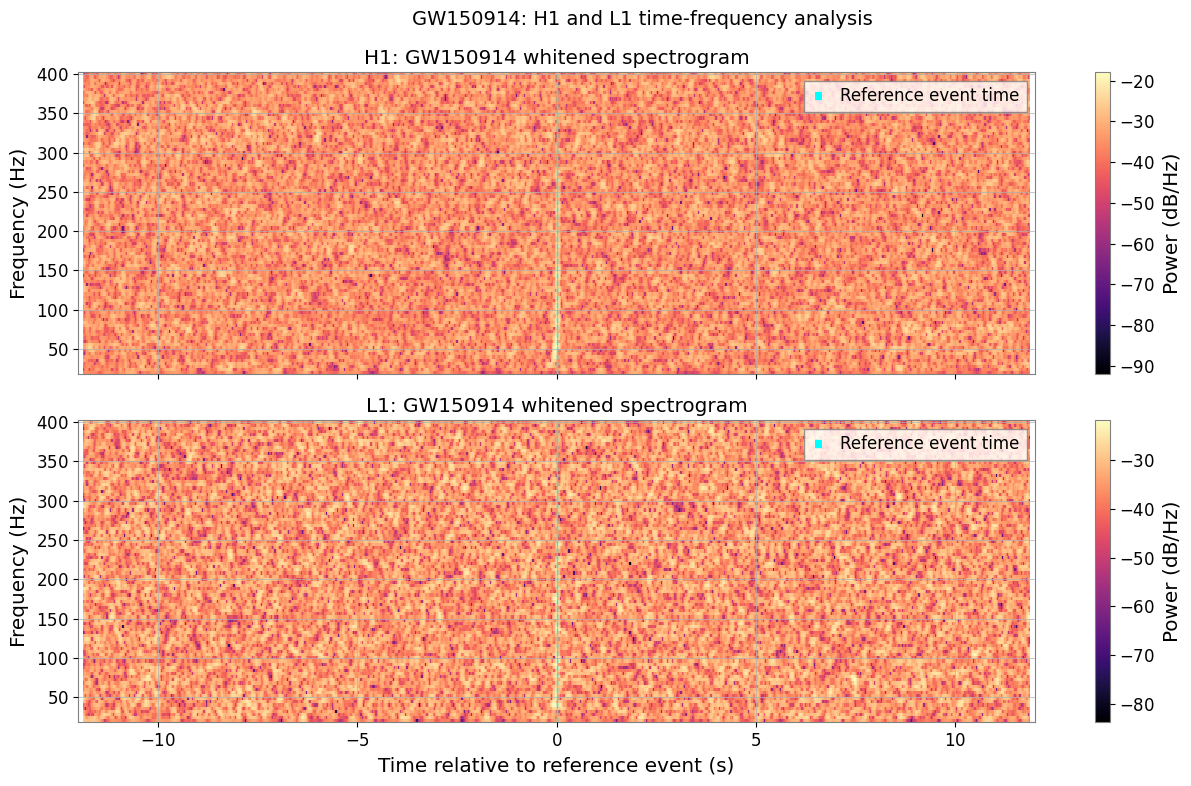

Saved: /content/gw150914_flagship/figures/phase5B_H1_L1_spectrograms.png
Spectrogram settings:
  Sampling frequency: 4096 Hz
  Frequency range: 20-400 Hz
  Window duration: 0.250 s
  Window overlap: 0.219 s


In [15]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.signal import spectrogram

# Project paths
PROJECT_DIR = Path("/content/gw150914_flagship")
PROCESSED_DIR = PROJECT_DIR / "processed"
FIGURES_DIR = PROJECT_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

FS = 4096
EVENT_GPS = 1126259462.4
DURATION = 24.0

# Spectrogram settings: moderate resolution, low computational cost
NPERSEG = 1024
NOVERLAP = 896
FMIN, FMAX = 20, 400

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)

for ax, det in zip(axes, ["H1", "L1"]):
    path = PROCESSED_DIR / f"{det}_GW150914_whitened.npy"

    if not path.exists():
        raise FileNotFoundError(f"Missing processed data: {path}")

    data = np.load(path)

    if data.ndim != 1 or len(data) != int(FS * DURATION):
        raise ValueError(
            f"{det}: unexpected data shape {data.shape}"
        )

    if not np.isfinite(data).all():
        raise ValueError(f"{det}: non-finite values detected")

    # Power spectral density of the whitened time series
    freqs, times, power = spectrogram(
        data,
        fs=FS,
        window="hann",
        nperseg=NPERSEG,
        noverlap=NOVERLAP,
        detrend="constant",
        scaling="density",
        mode="psd"
    )

    # Convert power to decibels for visualisation
    power_db = 10 * np.log10(np.maximum(power, 1e-20))

    freq_mask = (freqs >= FMIN) & (freqs <= FMAX)
    relative_times = times - DURATION / 2

    mesh = ax.pcolormesh(
        relative_times,
        freqs[freq_mask],
        power_db[freq_mask, :],
        shading="auto",
        cmap="magma"
    )

    ax.axvline(
        0, color="cyan", linestyle="--",
        linewidth=1, label="Reference event time"
    )

    ax.set_ylabel("Frequency (Hz)")
    ax.set_title(f"{det}: GW150914 whitened spectrogram")
    ax.legend(loc="upper right")
    fig.colorbar(mesh, ax=ax, label="Power (dB/Hz)")

axes[-1].set_xlabel("Time relative to reference event (s)")
axes[-1].set_xlim(-12, 12)

fig.suptitle(
    "GW150914: H1 and L1 time-frequency analysis",
    fontsize=14
)
fig.tight_layout()

output_path = FIGURES_DIR / "phase5B_H1_L1_spectrograms.png"
fig.savefig(output_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Saved:", output_path)
print("Spectrogram settings:")
print(f"  Sampling frequency: {FS} Hz")
print(f"  Frequency range: {FMIN}-{FMAX} Hz")
print(f"  Window duration: {NPERSEG / FS:.3f} s")
print(f"  Window overlap: {NOVERLAP / FS:.3f} s")


In [16]:

import numpy as np
from pathlib import Path
import importlib.util

PROJECT_DIR = Path("/content/gw150914_flagship")
RAW_DIR = PROJECT_DIR / "raw"
PROCESSED_DIR = PROJECT_DIR / "processed"

FS = 4096
OFFSETS = [300, 600, 900, 1200]

print("=== GW150914 AI DATASET AUDIT ===")

# Verify the raw event data
for det in ["H1", "L1"]:
    path = RAW_DIR / f"{det}_GW150914_raw.npy"

    if path.exists():
        x = np.load(path, mmap_mode="r")
        print(
            f"{det} raw: shape={x.shape}, "
            f"finite={np.isfinite(x).all()}"
        )
    else:
        print(f"MISSING: {path}")

# Verify independent background segments
for det in ["H1", "L1"]:
    for offset in OFFSETS:
        path = RAW_DIR / f"{det}_background_offset_{offset}s.npy"

        if path.exists():
            x = np.load(path, mmap_mode="r")
            print(
                f"{det} background +{offset}s: "
                f"samples={x.size}, "
                f"duration={x.size / FS:.2f}s, "
                f"finite={np.isfinite(x).all()}"
            )
        else:
            print(f"MISSING: {path}")

# Check whether physical waveform generation is available
print("\n=== DEPENDENCY CHECK ===")
print("PyCBC available:", importlib.util.find_spec("pycbc") is not None)
print("SciPy available:", importlib.util.find_spec("scipy") is not None)

# Confirm the existing whitened arrays
for det in ["H1", "L1"]:
    path = PROCESSED_DIR / f"{det}_GW150914_whitened.npy"

    if path.exists():
        x = np.load(path, mmap_mode="r")
        print(f"{det} whitened: {x.size} samples")

print("\nAudit complete. No data modified.")


=== GW150914 AI DATASET AUDIT ===
H1 raw: shape=(131072,), finite=True
L1 raw: shape=(131072,), finite=True
H1 background +300s: samples=524288, duration=128.00s, finite=True
H1 background +600s: samples=524288, duration=128.00s, finite=True
H1 background +900s: samples=524288, duration=128.00s, finite=True
H1 background +1200s: samples=524288, duration=128.00s, finite=True
L1 background +300s: samples=524288, duration=128.00s, finite=True
L1 background +600s: samples=524288, duration=128.00s, finite=True
L1 background +900s: samples=524288, duration=128.00s, finite=True
L1 background +1200s: samples=524288, duration=128.00s, finite=True

=== DEPENDENCY CHECK ===
PyCBC available: True
SciPy available: True
H1 whitened: 98304 samples
L1 whitened: 98304 samples

Audit complete. No data modified.


In [17]:

import numpy as np
from pathlib import Path
from pycbc.waveform import get_td_waveform

# --------------------------------------------------
# Configuration
# --------------------------------------------------
PROJECT_DIR = Path("/content/gw150914_flagship")
RAW_DIR = PROJECT_DIR / "raw"
DATASET_DIR = PROJECT_DIR / "dataset"
DATASET_DIR.mkdir(parents=True, exist_ok=True)

FS = 4096
WINDOW_SECONDS = 2
WINDOW = FS * WINDOW_SECONDS
OFFSETS = [300, 600, 900, 1200]
SAMPLES_PER_CLASS_PER_OFFSET = 128
SEED = 150914

rng = np.random.default_rng(SEED)

# Split by complete background offset, not random windows.
SPLITS = {
    "train": [300, 600],
    "validation": [900],
    "test": [1200],
}

# --------------------------------------------------
# Generate a simulated binary-black-hole waveform
# --------------------------------------------------
def make_waveform():
    mass1 = rng.uniform(25, 45)
    mass2 = rng.uniform(15, min(35, mass1))

    hp, hc = get_td_waveform(
        approximant="IMRPhenomD",
        mass1=float(mass1),
        mass2=float(mass2),
        distance=400,
        inclination=0,
        coa_phase=0,
        delta_t=1 / FS,
        f_lower=25
    )

    # Use the final two seconds, ending at merger.
    h = np.asarray(hp, dtype=np.float64)

    if len(h) > WINDOW:
        h = h[-WINDOW:]

    return h

# --------------------------------------------------
# Build positive and negative examples
# --------------------------------------------------
datasets = {
    split: {"X": [], "y": [], "offset": []}
    for split in SPLITS
}

for offset in OFFSETS:
    split = next(k for k, v in SPLITS.items() if offset in v)

    backgrounds = {}

    for det in ["H1", "L1"]:
        path = RAW_DIR / f"{det}_background_offset_{offset}s.npy"
        raw = np.load(path).astype(np.float32)

        if not np.isfinite(raw).all():
            raise ValueError(f"Non-finite values in {path}")

        # Retain raw strain structure; only apply a constant
        # segment-level scale for numerical stability.
        noise_scale = float(np.std(raw))

        if not np.isfinite(noise_scale) or noise_scale <= 0:
            raise ValueError(f"Invalid noise scale: {path}")

        backgrounds[det] = (raw, noise_scale)

    for label in [0, 1]:
        for _ in range(SAMPLES_PER_CLASS_PER_OFFSET):
            # Pick a common time window for the detector pair.
            max_start = min(
                len(backgrounds["H1"][0]),
                len(backgrounds["L1"][0])
            ) - WINDOW

            start = int(rng.integers(0, max_start + 1))
            pair = []

            # Generate one shared astrophysical signal per positive.
            h = make_waveform() if label == 1 else None

            # Put merger at a random position in the window.
            merger_idx = int(rng.integers(
                int(0.65 * WINDOW),
                int(0.90 * WINDOW)
            ))

            for det in ["H1", "L1"]:
                raw, noise_scale = backgrounds[det]
                segment = raw[start:start + WINDOW].copy()

                if label == 1:
                    signal = np.zeros(WINDOW, dtype=np.float64)

                    # Align waveform merger at merger_idx.
                    sig_start = merger_idx - len(h)
                    src_start = 0
                    dst_start = sig_start

                    if dst_start < 0:
                        src_start = -dst_start
                        dst_start = 0

                    usable = min(
                        len(h) - src_start,
                        WINDOW - dst_start
                    )

                    if usable > 0:
                        waveform = h[src_start:src_start + usable]

                        # Controlled augmentation strength, expressed
                        # relative to the raw background RMS.
                        target_peak = rng.uniform(0.5, 4.0) * noise_scale
                        peak = np.max(np.abs(waveform))

                        if peak > 0:
                            signal[dst_start:dst_start + usable] = (
                                waveform * target_peak / peak
                            )

                    # Approximate inter-detector arrival-time difference.
                    # The random offset is bounded to +/- 10 ms.
                    delay = (
                        int(rng.integers(-int(0.010 * FS),
                                         int(0.010 * FS) + 1))
                        if det == "L1" else 0
                    )

                    signal = np.roll(signal, delay)
                    segment += signal.astype(np.float32)

                # Constant background-derived scaling preserves
                # relative signal amplitudes within each segment.
                pair.append(segment / noise_scale)

            datasets[split]["X"].append(np.stack(pair).astype(np.float32))
            datasets[split]["y"].append(label)
            datasets[split]["offset"].append(offset)

    print(f"Finished offset {offset}s -> {split}")

# --------------------------------------------------
# Save datasets and verify
# --------------------------------------------------
for split, values in datasets.items():
    X = np.stack(values["X"])
    y = np.asarray(values["y"], dtype=np.int64)
    offsets = np.asarray(values["offset"], dtype=np.int64)

    # Shuffle within each split only.
    order = rng.permutation(len(y))
    X, y, offsets = X[order], y[order], offsets[order]

    out = DATASET_DIR / f"gw150914_{split}.npz"
    np.savez_compressed(
        out,
        X=X,
        y=y,
        offset=offsets,
        sampling_frequency=FS
    )

    print(
        f"{split}: X={X.shape}, "
        f"positive={int(y.sum())}, "
        f"negative={int((y == 0).sum())}, "
        f"finite={np.isfinite(X).all()}"
    )
    print("Saved:", out)

print("\nDataset generation complete.")


Finished offset 300s -> train
Finished offset 600s -> train
Finished offset 900s -> validation
Finished offset 1200s -> test
train: X=(512, 2, 8192), positive=256, negative=256, finite=True
Saved: /content/gw150914_flagship/dataset/gw150914_train.npz
validation: X=(256, 2, 8192), positive=128, negative=128, finite=True
Saved: /content/gw150914_flagship/dataset/gw150914_validation.npz
test: X=(256, 2, 8192), positive=128, negative=128, finite=True
Saved: /content/gw150914_flagship/dataset/gw150914_test.npz

Dataset generation complete.


## Dataset integrity and leakage audit

In [18]:

import numpy as np
from pathlib import Path

PROJECT_DIR = Path("/content/gw150914_flagship")
DATASET_DIR = PROJECT_DIR / "dataset"

FILES = {
    "train": DATASET_DIR / "gw150914_train.npz",
    "validation": DATASET_DIR / "gw150914_validation.npz",
    "test": DATASET_DIR / "gw150914_test.npz",
}

expected_offsets = {
    "train": {300, 600},
    "validation": {900},
    "test": {1200},
}

loaded = {}
all_passed = True

print("=== STAGE 5B: DATASET AUDIT ===")

for split, path in FILES.items():
    if not path.exists():
        raise FileNotFoundError(path)

    with np.load(path, allow_pickle=False) as d:
        X = d["X"]
        y = d["y"]
        offsets = d["offset"]
        fs = int(d["sampling_frequency"])

    checks = {
        "shape": X.shape == (len(y), 2, 8192),
        "labels": set(np.unique(y)).issubset({0, 1}),
        "balanced": np.sum(y == 0) == np.sum(y == 1),
        "finite": np.isfinite(X).all(),
        "sampling_rate": fs == 4096,
        "offsets": set(np.unique(offsets)) == expected_offsets[split],
    }

    all_passed &= all(checks.values())
    loaded[split] = (X, y, offsets)

    print(f"\n{split.upper()}:")
    print("  Shape:", X.shape)
    print("  Labels:", dict(zip(*np.unique(y, return_counts=True))))
    print("  Background offsets:", sorted(set(offsets.tolist())))
    print("  Mean/std:", round(float(X.mean()), 5),
          round(float(X.std()), 5))

    for name, passed in checks.items():
        print(f"  {'PASS' if passed else 'FAIL'}: {name}")

    for channel, det in enumerate(["H1", "L1"]):
        print(
            f"  {det}: mean={X[:, channel].mean():.5f}, "
            f"std={X[:, channel].std():.5f}"
        )

# Check that no background offset appears in multiple splits.
split_offsets = {
    name: set(values[2].tolist())
    for name, values in loaded.items()
}

for a, b in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test"),
]:
    overlap = split_offsets[a] & split_offsets[b]
    passed = len(overlap) == 0
    all_passed &= passed
    print(f"\n{'PASS' if passed else 'FAIL'}: "
          f"{a}/{b} offset separation; overlap={overlap}")

# Check whether positive and negative examples have different
# aggregate statistics. This is diagnostic, not a validity test.
X_train, y_train, _ = loaded["train"]

for label in [0, 1]:
    group = X_train[y_train == label]
    print(
        f"\nTrain label {label}: "
        f"RMS={np.sqrt(np.mean(group**2)):.5f}, "
        f"mean absolute amplitude={np.mean(np.abs(group)):.5f}"
    )

print("\nOVERALL STRUCTURAL AUDIT:",
      "PASS" if all_passed else "FAIL")
print("Note: structural PASS does not establish astrophysical validity.")


=== STAGE 5B: DATASET AUDIT ===

TRAIN:
  Shape: (512, 2, 8192)
  Labels: {np.int64(0): np.int64(256), np.int64(1): np.int64(256)}
  Background offsets: [300, 600]
  Mean/std: -2.30943 2.62427
  PASS: shape
  PASS: labels
  PASS: balanced
  PASS: finite
  PASS: sampling_rate
  PASS: offsets
  H1: mean=0.00178, std=1.26149
  L1: mean=-4.62063, std=1.22430

VALIDATION:
  Shape: (256, 2, 8192)
  Labels: {np.int64(0): np.int64(128), np.int64(1): np.int64(128)}
  Background offsets: [900]
  Mean/std: -2.41737 2.71849
  PASS: shape
  PASS: labels
  PASS: balanced
  PASS: finite
  PASS: sampling_rate
  PASS: offsets
  H1: mean=0.00730, std=1.23306
  L1: mean=-4.84203, std=1.22555

TEST:
  Shape: (256, 2, 8192)
  Labels: {np.int64(0): np.int64(128), np.int64(1): np.int64(128)}
  Background offsets: [1200]
  Mean/std: -2.53327 2.82621
  PASS: shape
  PASS: labels
  PASS: balanced
  PASS: finite
  PASS: sampling_rate
  PASS: offsets
  H1: mean=0.00022, std=1.23446
  L1: mean=-5.06677, std=1.2703

In [19]:

import numpy as np
from pathlib import Path

PROJECT_DIR = Path("/content/gw150914_flagship")
DATASET_DIR = PROJECT_DIR / "dataset"

for split in ["train", "validation", "test"]:
    source = DATASET_DIR / f"gw150914_{split}.npz"
    destination = DATASET_DIR / f"gw150914_{split}_centered.npz"

    with np.load(source, allow_pickle=False) as data:
        X = data["X"].astype(np.float32)
        y = data["y"]
        offsets = data["offset"]
        fs = data["sampling_frequency"]

    # Remove the DC offset independently for each detector window.
    X -= X.mean(axis=-1, keepdims=True)

    assert np.isfinite(X).all()
    assert np.max(np.abs(X.mean(axis=-1))) < 1e-4

    np.savez_compressed(
        destination,
        X=X,
        y=y,
        offset=offsets,
        sampling_frequency=fs
    )

    print(
        f"{split}: shape={X.shape}, "
        f"H1 mean={X[:, 0].mean():.5f}, "
        f"L1 mean={X[:, 1].mean():.5f}, "
        f"finite={np.isfinite(X).all()}"
    )
    print("Saved:", destination)

print("\nCorrected copies ready.")


train: shape=(512, 2, 8192), H1 mean=0.00000, L1 mean=-0.00000, finite=True
Saved: /content/gw150914_flagship/dataset/gw150914_train_centered.npz
validation: shape=(256, 2, 8192), H1 mean=-0.00000, L1 mean=-0.00000, finite=True
Saved: /content/gw150914_flagship/dataset/gw150914_validation_centered.npz
test: shape=(256, 2, 8192), H1 mean=-0.00000, L1 mean=0.00000, finite=True
Saved: /content/gw150914_flagship/dataset/gw150914_test_centered.npz

Corrected copies ready.


## train the CNN baseline

In [20]:

import json
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import roc_auc_score, average_precision_score
from pathlib import Path

PROJECT_DIR = Path("/content/gw150914_flagship")
DATASET_DIR = PROJECT_DIR / "dataset"
MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

torch.manual_seed(150914)
np.random.seed(150914)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

def load_split(name):
    with np.load(DATASET_DIR / f"gw150914_{name}_centered.npz") as d:
        return d["X"].astype(np.float32), d["y"].astype(np.int64)

X_train, y_train = load_split("train")
X_val, y_val = load_split("validation")

# Normalize using training data only; preserve relative signal amplitudes.
channel_mean = X_train.mean(axis=(0, 2), keepdims=True)
channel_std = X_train.std(axis=(0, 2), keepdims=True)
channel_std = np.maximum(channel_std, 1e-6)

X_train = (X_train - channel_mean) / channel_std
X_val = (X_val - channel_mean) / channel_std

train_loader = DataLoader(
    TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train)),
    batch_size=32, shuffle=True
)
val_loader = DataLoader(
    TensorDataset(torch.from_numpy(X_val), torch.from_numpy(y_val)),
    batch_size=64, shuffle=False
)

class CNNBaseline(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(2, 16, kernel_size=15, stride=2, padding=7),
            nn.BatchNorm1d(16), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(16, 32, kernel_size=9, stride=2, padding=4),
            nn.BatchNorm1d(32), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(32, 64, kernel_size=7, stride=2, padding=3),
            nn.BatchNorm1d(64), nn.ReLU(),
            nn.AdaptiveAvgPool1d(16)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 16, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.classifier(self.features(x)).squeeze(1)

model = CNNBaseline().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.BCEWithLogitsLoss()

best_auc = -1.0
best_state = None
patience, patience_used = 4, 0
history = []

for epoch in range(1, 13):
    model.train()
    train_loss = 0.0

    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.float().to(device)
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * len(yb)

    model.eval()
    val_logits, val_labels = [], []
    with torch.no_grad():
        for xb, yb in val_loader:
            logits = model(xb.to(device))
            val_logits.extend(logits.cpu().numpy())
            val_labels.extend(yb.numpy())

    probabilities = 1 / (1 + np.exp(-np.clip(val_logits, -30, 30)))
    val_auc = roc_auc_score(val_labels, probabilities)
    val_ap = average_precision_score(val_labels, probabilities)
    train_loss /= len(X_train)

    history.append({
        "epoch": epoch,
        "train_loss": float(train_loss),
        "validation_auc": float(val_auc),
        "validation_average_precision": float(val_ap)
    })
    print(
        f"Epoch {epoch:02d} | loss={train_loss:.4f} "
        f"| val_AUROC={val_auc:.4f} | val_AP={val_ap:.4f}"
    )

    if val_auc > best_auc:
        best_auc = val_auc
        patience_used = 0
        best_state = {
            k: v.detach().cpu().clone()
            for k, v in model.state_dict().items()
        }
    else:
        patience_used += 1
        if patience_used >= patience:
            print("Early stopping.")
            break

model.load_state_dict(best_state)
checkpoint_path = MODEL_DIR / "cnn_baseline.pt"
torch.save({
    "model_state_dict": model.state_dict(),
    "channel_mean": channel_mean,
    "channel_std": channel_std,
    "best_validation_auc": best_auc,
    "history": history,
    "sampling_frequency": 4096,
    "window_samples": 8192
}, checkpoint_path)

with open(MODEL_DIR / "cnn_baseline_history.json", "w") as f:
    json.dump(history, f, indent=2)

print("\nBest validation AUROC:", round(best_auc, 4))
print("Saved model:", checkpoint_path)
print("Training history saved.")


Device: cpu
Epoch 01 | loss=0.3261 | val_AUROC=0.9772 | val_AP=0.9831
Epoch 02 | loss=0.0479 | val_AUROC=0.9999 | val_AP=0.9999
Epoch 03 | loss=0.0137 | val_AUROC=1.0000 | val_AP=1.0000
Epoch 04 | loss=0.0104 | val_AUROC=1.0000 | val_AP=1.0000
Epoch 05 | loss=0.0059 | val_AUROC=1.0000 | val_AP=1.0000
Epoch 06 | loss=0.0016 | val_AUROC=1.0000 | val_AP=1.0000
Epoch 07 | loss=0.0012 | val_AUROC=1.0000 | val_AP=1.0000
Early stopping.

Best validation AUROC: 1.0
Saved model: /content/gw150914_flagship/models/cnn_baseline.pt
Training history saved.


## independent test evaluation

In [21]:

import json
import numpy as np
import torch
import torch.nn as nn
from pathlib import Path
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    accuracy_score, precision_score, recall_score,
    confusion_matrix, classification_report
)

PROJECT_DIR = Path("/content/gw150914_flagship")
MODEL_DIR = PROJECT_DIR / "models"
DATASET_DIR = PROJECT_DIR / "dataset"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class CNNBaseline(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(2, 16, 15, stride=2, padding=7),
            nn.BatchNorm1d(16), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(16, 32, 9, stride=2, padding=4),
            nn.BatchNorm1d(32), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(32, 64, 7, stride=2, padding=3),
            nn.BatchNorm1d(64), nn.ReLU(),
            nn.AdaptiveAvgPool1d(16)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(64 * 16, 64),
            nn.ReLU(), nn.Dropout(0.3), nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.classifier(self.features(x)).squeeze(1)

checkpoint = torch.load(
    MODEL_DIR / "cnn_baseline.pt",
    map_location=device,
    weights_only=False
)
model = CNNBaseline().to(device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

with np.load(DATASET_DIR / "gw150914_test_centered.npz") as data:
    X_test = data["X"].astype(np.float32)
    y_test = data["y"].astype(np.int64)
    test_offsets = data["offset"]

X_test = (
    X_test - checkpoint["channel_mean"]
) / np.maximum(checkpoint["channel_std"], 1e-6)

with torch.no_grad():
    logits = model(torch.from_numpy(X_test).to(device)).cpu().numpy()

probabilities = 1 / (1 + np.exp(-np.clip(logits, -30, 30)))
predictions = (probabilities >= 0.5).astype(np.int64)

results = {
    "test_AUROC": float(roc_auc_score(y_test, probabilities)),
    "test_average_precision": float(average_precision_score(y_test, probabilities)),
    "test_accuracy": float(accuracy_score(y_test, predictions)),
    "test_precision": float(precision_score(y_test, predictions, zero_division=0)),
    "test_recall": float(recall_score(y_test, predictions, zero_division=0)),
    "confusion_matrix": confusion_matrix(y_test, predictions).tolist(),
    "test_offsets_seconds": sorted(np.unique(test_offsets).astype(int).tolist()),
    "test_examples": int(len(y_test))
}

print("INDEPENDENT TEST RESULTS")
for key, value in results.items():
    print(f"{key}: {value}")

print("\nClassification report:")
print(classification_report(
    y_test, predictions,
    target_names=["Background", "Injection"],
    zero_division=0
))

with open(MODEL_DIR / "cnn_baseline_test_results.json", "w") as f:
    json.dump(results, f, indent=2)

print("Saved:", MODEL_DIR / "cnn_baseline_test_results.json")
print("\nPrediction probability ranges:")
for label, name in [(0, "Background"), (1, "Injection")]:
    p = probabilities[y_test == label]
    print(f"{name}: min={p.min():.4f}, median={np.median(p):.4f}, max={p.max():.4f}")


INDEPENDENT TEST RESULTS
test_AUROC: 1.0
test_average_precision: 1.0
test_accuracy: 0.9765625
test_precision: 1.0
test_recall: 0.953125
confusion_matrix: [[128, 0], [6, 122]]
test_offsets_seconds: [1200]
test_examples: 256

Classification report:
              precision    recall  f1-score   support

  Background       0.96      1.00      0.98       128
   Injection       1.00      0.95      0.98       128

    accuracy                           0.98       256
   macro avg       0.98      0.98      0.98       256
weighted avg       0.98      0.98      0.98       256

Saved: /content/gw150914_flagship/models/cnn_baseline_test_results.json

Prediction probability ranges:
Background: min=0.0002, median=0.0004, max=0.0013
Injection: min=0.0086, median=0.9999, max=1.0000


## save the results and inspect the six missed injections

In [22]:

import numpy as np
from pathlib import Path

PROJECT_DIR = Path("/content/gw150914_flagship")
DATASET_DIR = PROJECT_DIR / "dataset"
MODEL_DIR = PROJECT_DIR / "models"

with np.load(DATASET_DIR / "gw150914_test_centered.npz") as d:
    X = d["X"].astype(np.float32)
    y = d["y"].astype(int)
    offsets = d["offset"]

# Reproduce the saved model's predictions
import torch
checkpoint = torch.load(
    MODEL_DIR / "cnn_baseline.pt",
    map_location="cpu",
    weights_only=False
)

# Use the same model architecture as training
import torch.nn as nn

class CNNBaseline(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(2,16,15,stride=2,padding=7),
            nn.BatchNorm1d(16), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(16,32,9,stride=2,padding=4),
            nn.BatchNorm1d(32), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(32,64,7,stride=2,padding=3),
            nn.BatchNorm1d(64), nn.ReLU(),
            nn.AdaptiveAvgPool1d(16)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(1024,64),
            nn.ReLU(), nn.Dropout(0.3), nn.Linear(64,1)
        )
    def forward(self,x):
        return self.classifier(self.features(x)).squeeze(1)

model = CNNBaseline()
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

mean = checkpoint["channel_mean"]
std = np.maximum(checkpoint["channel_std"], 1e-6)
Xn = (X - mean) / std

with torch.no_grad():
    logits = model(torch.from_numpy(Xn)).numpy()
prob = 1 / (1 + np.exp(-np.clip(logits, -30, 30)))

missed = np.where((y == 1) & (prob < 0.5))[0]
detected = np.where((y == 1) & (prob >= 0.5))[0]

print("Missed injection count:", len(missed))
print("Missed test indices:", missed.tolist())
print("Missed injection probabilities:", np.round(prob[missed], 5).tolist())
print("Detected injection count:", len(detected))
print("Median probability — detected:", round(float(np.median(prob[detected])), 5))
print("Median probability — missed:", round(float(np.median(prob[missed])), 5))
print("Test background median probability:",
      round(float(np.median(prob[y == 0])), 5))

print("\nReminder: these are synthetic injections; real-event generalization remains untested.")


Missed injection count: 6
Missed test indices: [24, 75, 77, 154, 196, 238]
Missed injection probabilities: [0.21755999326705933, 0.29030001163482666, 0.24278999865055084, 0.008550000376999378, 0.20343999564647675, 0.1112700030207634]
Detected injection count: 122
Median probability — detected: 0.99992
Median probability — missed: 0.2105
Test background median probability: 0.00038

Reminder: these are synthetic injections; real-event generalization remains untested.


In [23]:

import numpy as np
from pathlib import Path

DATASET_DIR = Path("/content/gw150914_flagship/dataset")

with np.load(DATASET_DIR / "gw150914_test_centered.npz") as d:
    X = d["X"].astype(np.float32)
    y = d["y"].astype(int)

missed_idx = np.array([24, 75, 77, 154, 196, 238])
detected_idx = np.where((y == 1) & ~np.isin(np.arange(len(y)), missed_idx))[0]

def describe(indices, label):
    subset = X[indices]
    rms = np.sqrt(np.mean(subset**2, axis=-1))
    peak = np.max(np.abs(subset), axis=-1)
    print(f"\n{label}: {len(indices)} examples")
    print("Median H1 RMS:", round(float(np.median(rms[:, 0])), 4))
    print("Median L1 RMS:", round(float(np.median(rms[:, 1])), 4))
    print("Median H1 peak:", round(float(np.median(peak[:, 0])), 4))
    print("Median L1 peak:", round(float(np.median(peak[:, 1])), 4))

describe(missed_idx, "Missed injections")
describe(detected_idx, "Detected injections")

print("\nMissed injection per-example statistics:")
for i in missed_idx:
    rms = np.sqrt(np.mean(X[i]**2, axis=-1))
    peak = np.max(np.abs(X[i]), axis=-1)
    print(
        f"index={i:3d} | H1 RMS={rms[0]:.3f} | L1 RMS={rms[1]:.3f} "
        f"| H1 peak={peak[0]:.3f} | L1 peak={peak[1]:.3f}"
    )

print("\nAudit note: RMS and peak values are diagnostic only, not calibrated GW SNR.")



Missed injections: 6 examples
Median H1 RMS: 0.9222
Median L1 RMS: 0.9717
Median H1 peak: 2.5255
Median L1 peak: 2.9469

Detected injections: 122 examples
Median H1 RMS: 1.451
Median L1 RMS: 1.4731
Median H1 peak: 3.937
Median L1 peak: 4.3725

Missed injection per-example statistics:
index= 24 | H1 RMS=0.930 | L1 RMS=0.735 | H1 peak=2.619 | L1 peak=2.475
index= 75 | H1 RMS=0.914 | L1 RMS=1.002 | H1 peak=2.473 | L1 peak=2.947
index= 77 | H1 RMS=0.991 | L1 RMS=0.940 | H1 peak=2.255 | L1 peak=2.947
index=154 | H1 RMS=0.855 | L1 RMS=1.158 | H1 peak=2.577 | L1 peak=3.613
index=196 | H1 RMS=0.825 | L1 RMS=1.258 | H1 peak=2.402 | L1 peak=3.143
index=238 | H1 RMS=1.089 | L1 RMS=0.942 | H1 peak=3.039 | L1 peak=2.903

Audit note: RMS and peak values are diagnostic only, not calibrated GW SNR.


In [24]:

from pathlib import Path
import numpy as np

PROJECT_DIR = Path("/content/gw150914_flagship")
DATASET_DIR = PROJECT_DIR / "dataset"

for split in ["train", "validation", "test"]:
    path = DATASET_DIR / f"gw150914_{split}.npz"
    with np.load(path, allow_pickle=False) as d:
        print(f"\n{split.upper()}")
        print("Keys:", d.files)
        print("X shape:", d["X"].shape)
        print("Label counts:", {
            int(k): int(v) for k, v in zip(*np.unique(d["y"], return_counts=True))
        })
        print("Offsets:", np.unique(d["offset"]).tolist())
        print("Sampling frequency:", np.unique(d["sampling_frequency"]).tolist())

print("\nGeneration scripts and related files:")
for folder in [PROJECT_DIR, PROJECT_DIR / "reports"]:
    if folder.exists():
        for p in sorted(folder.glob("*.py")):
            print(p)
        for p in sorted(folder.glob("*.json")):
            print(p)



TRAIN
Keys: ['X', 'y', 'offset', 'sampling_frequency']
X shape: (512, 2, 8192)
Label counts: {0: 256, 1: 256}
Offsets: [300, 600]
Sampling frequency: [4096]

VALIDATION
Keys: ['X', 'y', 'offset', 'sampling_frequency']
X shape: (256, 2, 8192)
Label counts: {0: 128, 1: 128}
Offsets: [900]
Sampling frequency: [4096]

TEST
Keys: ['X', 'y', 'offset', 'sampling_frequency']
X shape: (256, 2, 8192)
Label counts: {0: 128, 1: 128}
Offsets: [1200]
Sampling frequency: [4096]

Generation scripts and related files:
/content/gw150914_flagship/reports/GW150914_event_manifest.json
/content/gw150914_flagship/reports/asd_comparison.json
/content/gw150914_flagship/reports/candidate_background_manifest.json
/content/gw150914_flagship/reports/official_data_flag_check.json
/content/gw150914_flagship/reports/raw_data_inspection.json


In [25]:

import json
from pathlib import Path

PROJECT_DIR = Path("/content/gw150914_flagship")
REPORT_DIR = PROJECT_DIR / "reports"

for filename in [
    "candidate_background_manifest.json",
    "GW150914_event_manifest.json",
    "official_data_flag_check.json"
]:
    path = REPORT_DIR / filename
    print(f"\n{'='*20} {filename} {'='*20}")

    if not path.exists():
        print("Not found")
        continue

    with open(path) as f:
        data = json.load(f)

    print(json.dumps(data, indent=2)[:6000])



==================== candidate_background_manifest.json ====================
{
  "event": "GW150914",
  "source": "GWOSC public strain data via GWpy",
  "sample_rate_hz_requested": 4096,
  "segment_duration_seconds_requested": 128,
  "selection_note": "Candidate off-source periods. Not yet certified glitch-free or confirmed suitable for training.",
  "segments": [
    {
      "offset_before_event_seconds": 300,
      "requested_start_gps": 1126259098.4,
      "requested_end_gps": 1126259226.4,
      "detectors": {
        "H1": {
          "file": "H1_background_offset_300s.npy",
          "sample_count": 524288,
          "sample_rate_hz": 4096.0,
          "actual_start_gps": 1126259098.3999023,
          "last_sample_gps": 1126259226.3996582,
          "finite_values": true,
          "mean": 6.316694619343666e-23,
          "standard_deviation": 2.117184798259351e-19
        },
        "L1": {
          "file": "L1_background_offset_300s.npy",
          "sample_count": 524288,
   

In [26]:

import json
from pathlib import Path

path = Path("/content/gw150914_flagship/reports/candidate_background_manifest.json")

if path.exists():
    data = json.loads(path.read_text())
    print(json.dumps(data, indent=2)[:10000])
else:
    print("Candidate background manifest not found.")

print("\nRaw background files:")
raw_dir = Path("/content/gw150914_flagship/raw")
for p in sorted(raw_dir.glob("*background*")):
    print(f"{p.name}: {p.stat().st_size / (1024**2):.2f} MB")


{
  "event": "GW150914",
  "source": "GWOSC public strain data via GWpy",
  "sample_rate_hz_requested": 4096,
  "segment_duration_seconds_requested": 128,
  "selection_note": "Candidate off-source periods. Not yet certified glitch-free or confirmed suitable for training.",
  "segments": [
    {
      "offset_before_event_seconds": 300,
      "requested_start_gps": 1126259098.4,
      "requested_end_gps": 1126259226.4,
      "detectors": {
        "H1": {
          "file": "H1_background_offset_300s.npy",
          "sample_count": 524288,
          "sample_rate_hz": 4096.0,
          "actual_start_gps": 1126259098.3999023,
          "last_sample_gps": 1126259226.3996582,
          "finite_values": true,
          "mean": 6.316694619343666e-23,
          "standard_deviation": 2.117184798259351e-19
        },
        "L1": {
          "file": "L1_background_offset_300s.npy",
          "sample_count": 524288,
          "sample_rate_hz": 4096.0,
          "actual_start_gps": 1126259098.3999

In [27]:

import numpy as np
import json
from pathlib import Path

PROJECT_DIR = Path("/content/gw150914_flagship")
RAW_DIR = PROJECT_DIR / "raw"
REPORT_DIR = PROJECT_DIR / "reports"
FS = 4096
WINDOW_SECONDS = 1
WINDOW = FS * WINDOW_SECONDS

results = {}

for offset in [300, 600, 900, 1200]:
    for detector in ["H1", "L1"]:
        path = RAW_DIR / f"{detector}_background_offset_{offset}s.npy"
        x = np.load(path).astype(np.float64)

        # Remove the segment-wide DC offset for diagnostics.
        centered = x - np.median(x)
        window_rms = np.sqrt(
            np.mean(centered[:len(centered) // WINDOW * WINDOW]
                    .reshape(-1, WINDOW) ** 2, axis=1)
        )

        robust_scale = 1.4826 * np.median(
            np.abs(centered - np.median(centered))
        )
        peak_ratio = (
            float(np.max(np.abs(centered)) / robust_scale)
            if robust_scale > 0 else None
        )

        record = {
            "finite": bool(np.isfinite(x).all()),
            "samples": int(len(x)),
            "median_strain": float(np.median(x)),
            "robust_scale": float(robust_scale),
            "peak_to_robust_scale": peak_ratio,
            "window_rms_min": float(window_rms.min()),
            "window_rms_median": float(np.median(window_rms)),
            "window_rms_max": float(window_rms.max()),
            "windows_over_3x_median": int(
                np.sum(window_rms > 3 * np.median(window_rms))
            )
        }

        results[f"{detector}_offset_{offset}s"] = record
        print(
            f"{detector} offset={offset:4d}s | "
            f"finite={record['finite']} | "
            f"peak/robust={peak_ratio:.1f} | "
            f"1s RMS median={record['window_rms_median']:.3e} | "
            f"max={record['window_rms_max']:.3e} | "
            f"high-RMS windows={record['windows_over_3x_median']}"
        )

out = REPORT_DIR / "background_quality_screen.json"
out.write_text(json.dumps(results, indent=2))
print("\nSaved screening report:", out)
print("Screening only — this does not certify segments as glitch-free.")


H1 offset= 300s | finite=True | peak/robust=4.8 | 1s RMS median=1.997e-19 | max=3.700e-19 | high-RMS windows=0
L1 offset= 300s | finite=True | peak/robust=5.3 | 1s RMS median=2.006e-19 | max=4.422e-19 | high-RMS windows=0
H1 offset= 600s | finite=True | peak/robust=5.4 | 1s RMS median=1.925e-19 | max=4.539e-19 | high-RMS windows=0
L1 offset= 600s | finite=True | peak/robust=6.0 | 1s RMS median=2.100e-19 | max=6.518e-19 | high-RMS windows=1
H1 offset= 900s | finite=True | peak/robust=4.0 | 1s RMS median=1.877e-19 | max=3.647e-19 | high-RMS windows=0
L1 offset= 900s | finite=True | peak/robust=5.0 | 1s RMS median=1.964e-19 | max=3.977e-19 | high-RMS windows=0
H1 offset=1200s | finite=True | peak/robust=4.2 | 1s RMS median=1.865e-19 | max=3.966e-19 | high-RMS windows=0
L1 offset=1200s | finite=True | peak/robust=4.7 | 1s RMS median=1.948e-19 | max=3.295e-19 | high-RMS windows=0

Saved screening report: /content/gw150914_flagship/reports/background_quality_screen.json
Screening only — this

In [28]:

import numpy as np
import json
from pathlib import Path
from scipy.signal import butter, sosfiltfilt

PROJECT_DIR = Path("/content/gw150914_flagship")
RAW_DIR = PROJECT_DIR / "raw"
REPORT_DIR = PROJECT_DIR / "reports"

FS = 4096
WINDOW = 2 * FS
sos = butter(4, [20, 500], btype="bandpass", fs=FS, output="sos")

window_index = []

for offset in [300, 600, 900, 1200]:
    h1 = np.load(RAW_DIR / f"H1_background_offset_{offset}s.npy").astype(np.float64)
    l1 = np.load(RAW_DIR / f"L1_background_offset_{offset}s.npy").astype(np.float64)

    # Apply the same filter independently to each full segment.
    h1_f = sosfiltfilt(sos, h1)
    l1_f = sosfiltfilt(sos, l1)

    # Use only complete, aligned 2-second windows.
    n_windows = min(len(h1_f), len(l1_f)) // WINDOW

    for w in range(n_windows):
        start = w * WINDOW
        end = start + WINDOW
        a = h1_f[start:end].copy()
        b = l1_f[start:end].copy()

        # Local centering prevents segment DC offsets entering the model.
        a -= np.mean(a)
        b -= np.mean(b)

        rms_h1 = float(np.sqrt(np.mean(a**2)))
        rms_l1 = float(np.sqrt(np.mean(b**2)))

        window_index.append({
            "offset_seconds_before_event": offset,
            "window_index": w,
            "start_sample": start,
            "end_sample": end,
            "start_seconds_within_segment": w * 2,
            "H1_rms": rms_h1,
            "L1_rms": rms_l1,
            "finite": bool(np.isfinite(a).all() and np.isfinite(b).all())
        })

out = REPORT_DIR / "filtered_background_window_index.json"
out.write_text(json.dumps(window_index, indent=2))

print("Indexed windows:", len(window_index))
print("Expected windows:", 4 * 64)
print("All finite:", all(r["finite"] for r in window_index))
print("Saved:", out)
print("\nFirst entry:")
print(json.dumps(window_index[0], indent=2))


Indexed windows: 256
Expected windows: 256
All finite: True
Saved: /content/gw150914_flagship/reports/filtered_background_window_index.json

First entry:
{
  "offset_seconds_before_event": 300,
  "window_index": 0,
  "start_sample": 0,
  "end_sample": 8192,
  "start_seconds_within_segment": 0,
  "H1_rms": 1.940303643720518e-21,
  "L1_rms": 1.6273616010398226e-20,
  "finite": true
}


## verify waveform-generation support

In [29]:

import json
import numpy as np
from pathlib import Path

from pycbc.waveform import get_td_waveform

PROJECT_DIR = Path("/content/gw150914_flagship")
REPORT_DIR = PROJECT_DIR / "reports"
FS = 4096

hp, hc = get_td_waveform(
    approximant="IMRPhenomD",
    mass1=36.0,
    mass2=29.0,
    distance=400,
    inclination=0,
    coa_phase=0,
    delta_t=1 / FS,
    f_lower=25
)

hp = np.asarray(hp, dtype=np.float64)
hc = np.asarray(hc, dtype=np.float64)

manifest = {
    "approximant": "IMRPhenomD",
    "mass1_solar": 36.0,
    "mass2_solar": 29.0,
    "distance_mpc": 400,
    "inclination_rad": 0,
    "coalescence_phase_rad": 0,
    "sampling_frequency_hz": FS,
    "lower_frequency_hz": 25,
    "plus_samples": int(len(hp)),
    "cross_samples": int(len(hc)),
    "duration_seconds": float(len(hp) / FS),
    "plus_peak": float(np.max(np.abs(hp))),
    "cross_peak": float(np.max(np.abs(hc))),
    "finite": bool(np.isfinite(hp).all() and np.isfinite(hc).all()),
    "note": (
        "Waveform-generation check only. Detector antenna responses, "
        "inter-detector time delay, calibration, and injection SNR "
        "must be handled explicitly before scientific evaluation."
    )
}

out = REPORT_DIR / "waveform_generation_check.json"
out.write_text(json.dumps(manifest, indent=2))

print(json.dumps(manifest, indent=2))
print("\nSaved:", out)


{
  "approximant": "IMRPhenomD",
  "mass1_solar": 36.0,
  "mass2_solar": 29.0,
  "distance_mpc": 400,
  "inclination_rad": 0,
  "coalescence_phase_rad": 0,
  "sampling_frequency_hz": 4096,
  "lower_frequency_hz": 25,
  "plus_samples": 65536,
  "cross_samples": 65536,
  "duration_seconds": 16.0,
  "plus_peak": 1.8940241695619903e-21,
  "cross_peak": 1.9104277552586635e-21,
  "finite": true,
  "note": "Waveform-generation check only. Detector antenna responses, inter-detector time delay, calibration, and injection SNR must be handled explicitly before scientific evaluation."
}

Saved: /content/gw150914_flagship/reports/waveform_generation_check.json


In [30]:

import json
import numpy as np
from pathlib import Path

PROJECT_DIR = Path("/content/gw150914_flagship")
RAW_DIR = PROJECT_DIR / "raw"
REPORT_DIR = PROJECT_DIR / "reports"
DATASET_DIR = PROJECT_DIR / "dataset"
DATASET_DIR.mkdir(parents=True, exist_ok=True)

manifest_path = REPORT_DIR / "waveform_generation_check.json"

if not manifest_path.exists():
    raise FileNotFoundError(
        "Run the waveform-generation check cell first."
    )

manifest = json.loads(manifest_path.read_text())
assert manifest["finite"], "Waveform check reported non-finite values."

required_files = [
    RAW_DIR / f"{detector}_background_offset_{offset}s.npy"
    for offset in [300, 600, 900, 1200]
    for detector in ["H1", "L1"]
]

missing = [str(p) for p in required_files if not p.exists()]
if missing:
    raise FileNotFoundError(f"Missing background files: {missing}")

# Confirm sampling and dimensions before processing.
for p in required_files:
    x = np.load(p, mmap_mode="r")
    assert x.ndim == 1 and len(x) >= 8192, f"Invalid data: {p.name}"
    assert np.isfinite(x).all(), f"Non-finite values: {p.name}"
    print(f"OK {p.name}: {len(x):,} samples")

print("\nWaveform check:", manifest["approximant"])
print("Sampling rate:", manifest["sampling_frequency_hz"], "Hz")
print("All required background files are available.")
print("Ready for the new filtered/whitened dataset.")


OK H1_background_offset_300s.npy: 524,288 samples
OK L1_background_offset_300s.npy: 524,288 samples
OK H1_background_offset_600s.npy: 524,288 samples
OK L1_background_offset_600s.npy: 524,288 samples
OK H1_background_offset_900s.npy: 524,288 samples
OK L1_background_offset_900s.npy: 524,288 samples
OK H1_background_offset_1200s.npy: 524,288 samples
OK L1_background_offset_1200s.npy: 524,288 samples

Waveform check: IMRPhenomD
Sampling rate: 4096 Hz
All required background files are available.
Ready for the new filtered/whitened dataset.


In [31]:

import json
import numpy as np
from pathlib import Path
from scipy.signal import welch

from pycbc.waveform import get_td_waveform
from pycbc.detector import Detector

PROJECT = Path("/content/gw150914_flagship")
RAW = PROJECT / "raw"
DATA = PROJECT / "dataset"
REPORTS = PROJECT / "reports"
DATA.mkdir(exist_ok=True, parents=True)
REPORTS.mkdir(exist_ok=True, parents=True)

FS = 4096
WIN = 2 * FS
CTX = 4 * FS
GPS_EVENT = 1126259462.4
OFFSETS = {"train": [300, 600], "validation": [900], "test": [1200]}
PAIRS_PER_OFFSET = 128
rng = np.random.default_rng(15091426)
detectors = {name: Detector(name) for name in ["H1", "L1"]}

# PSD-based whitening operator, estimated from each real background segment.
def whiten_context(x, psd_freq, psd):
    f = np.fft.rfftfreq(len(x), 1 / FS)
    p = np.interp(f, psd_freq, psd)
    valid = (f >= 20) & (f <= 500)
    floor = max(np.median(p[valid]) * 1e-6, 1e-100)
    transfer = np.zeros_like(f)
    transfer[valid] = 1.0 / np.sqrt(np.maximum(p[valid], floor))
    return np.fft.irfft(np.fft.rfft(x) * transfer, n=len(x))

# Load backgrounds and cache their whitened 2-second windows.
backgrounds = {}
for offset in sorted(set(sum(OFFSETS.values(), []))):
    gps_start = GPS_EVENT - offset - 64
    for det in ["H1", "L1"]:
        raw = np.load(RAW / f"{det}_background_offset_{offset}s.npy").astype(np.float64)
        pf, psd = welch(
            raw, fs=FS, nperseg=CTX, noverlap=CTX // 2,
            average="median"
        )

        starts = np.arange(0, len(raw) - CTX + 1, WIN)
        contexts, windows = [], []
        for start in starts:
            context = raw[start:start + CTX]
            white = whiten_context(context, pf, psd)
            central = white[FS:3 * FS].copy()
            central -= central.mean()
            contexts.append(context)
            windows.append(central)

        scale = float(np.median([
            np.sqrt(np.mean(w**2)) for w in windows
        ]))
        if not np.isfinite(scale) or scale <= 0:
            raise ValueError(f"Invalid whitening scale: {det}, {offset}")

        backgrounds[(offset, det)] = {
            "raw": raw, "gps_start": gps_start, "psd_freq": pf,
            "psd": psd, "starts": starts, "contexts": contexts,
            "windows": windows, "scale": scale
        }
        print(f"Prepared {det} offset {offset}s: {len(windows)} windows")

# Build paired examples: each injection uses the same noise window
# as its corresponding background-only example.
for split, offsets in OFFSETS.items():
    X_items, y_items, metadata = [], [], []

    for offset in offsets:
        for pair_id in range(PAIRS_PER_OFFSET):
            available = backgrounds[(offset, "H1")]["starts"]
            j = int(rng.integers(len(available)))
            start = int(available[j])

            noise = {}
            contexts = {}
            for det in ["H1", "L1"]:
                b = backgrounds[(offset, det)]
                contexts[det] = b["raw"][start:start + CTX].copy()
                noise[det] = b["windows"][j] / b["scale"]

            # Negative example
            X_items.append(np.stack([noise["H1"], noise["L1"]]).astype(np.float32))
            y_items.append(0)
            metadata.append({
                "split": split, "label": 0, "pair_id": pair_id,
                "background_offset_seconds": offset,
                "context_start_sample": start,
                "whitening": "4-second median-Welch PSD; 20-500 Hz",
                "injection": None
            })

            # Random compact-binary waveform and sky location
            m1 = float(rng.uniform(25, 45))
            m2 = float(rng.uniform(15, min(35, m1)))
            distance = float(rng.uniform(300, 800))
            ra = float(rng.uniform(0, 2 * np.pi))
            dec = float(np.arcsin(rng.uniform(-1, 1)))
            psi = float(rng.uniform(0, 2 * np.pi))

            hp, hc = get_td_waveform(
                approximant="IMRPhenomD",
                mass1=m1, mass2=m2, distance=distance,
                inclination=float(rng.uniform(0, np.pi)),
                coa_phase=float(rng.uniform(0, 2 * np.pi)),
                delta_t=1 / FS, f_lower=30
            )
            hp, hc = np.asarray(hp), np.asarray(hc)

            merger_in_window = int(rng.integers(int(0.65 * FS), int(1.35 * FS)))
            gps_merger = (
                backgrounds[(offset, "H1")]["gps_start"]
                + (start + FS + merger_in_window) / FS
            )

            signal = {}
            response_info = {}
            for det in ["H1", "L1"]:
                fp, fc = detectors[det].antenna_pattern(ra, dec, psi, gps_merger)
                delay = detectors[det].time_delay_from_earth_center(ra, dec, gps_merger)
                local_merger = FS + merger_in_window + int(round(delay * FS))

                waveform = fp * hp + fc * hc
                signal_context = np.zeros(CTX, dtype=np.float64)
                ncopy = min(len(waveform), local_merger + 1)
                if ncopy > 0:
                    end = local_merger + 1
                    signal_context[end - ncopy:end] = waveform[-ncopy:]

                b = backgrounds[(offset, det)]
                signal[det] = whiten_context(
                    signal_context, b["psd_freq"], b["psd"]
                )[FS:3 * FS] / b["scale"]
                response_info[det] = {
                    "antenna_plus": float(fp),
                    "antenna_cross": float(fc),
                    "delay_seconds_from_geocenter": float(delay)
                }

            # Set a controlled range of whitened signal norms.
            # This is NOT a calibrated matched-filter SNR.
            raw_norm = float(np.sqrt(sum(np.sum(s**2) for s in signal.values())))
            target_norm = float(rng.uniform(6, 18))
            amplitude_scale = target_norm / max(raw_norm, 1e-30)

            positive = {}
            for det in ["H1", "L1"]:
                b = backgrounds[(offset, det)]
                injected_context = contexts[det] + amplitude_scale * (
                    np.pad(
                        np.zeros(0), (0, 0)
                    ) if False else 0
                )
                # Reconstruct the detector-projected waveform in raw strain units.
                fp = response_info[det]["antenna_plus"]
                fc = response_info[det]["antenna_cross"]
                delay = response_info[det]["delay_seconds_from_geocenter"]
                local_merger = FS + merger_in_window + int(round(delay * FS))
                waveform = fp * hp + fc * hc
                raw_signal = np.zeros(CTX, dtype=np.float64)
                ncopy = min(len(waveform), local_merger + 1)
                if ncopy > 0:
                    raw_signal[local_merger + 1 - ncopy:local_merger + 1] = waveform[-ncopy:]

                injected_context = contexts[det] + amplitude_scale * raw_signal
                white = whiten_context(injected_context, b["psd_freq"], b["psd"])
                positive[det] = white[FS:3 * FS] / b["scale"]
                positive[det] -= positive[det].mean()

            X_items.append(np.stack([positive["H1"], positive["L1"]]).astype(np.float32))
            y_items.append(1)
            metadata.append({
                "split": split, "label": 1, "pair_id": pair_id,
                "background_offset_seconds": offset,
                "context_start_sample": start,
                "whitening": "4-second median-Welch PSD; 20-500 Hz",
                "injection": {
                    "approximant": "IMRPhenomD",
                    "mass1_solar": m1, "mass2_solar": m2,
                    "distance_mpc_parameter": distance,
                    "right_ascension_rad": ra,
                    "declination_rad": dec,
                    "polarization_rad": psi,
                    "geocentric_merger_gps": float(gps_merger),
                    "merger_sample_in_2s_window": merger_in_window,
                    "detector_responses": response_info,
                    "amplitude_scale": float(amplitude_scale),
                    "target_whitened_signal_norm_not_calibrated_snr": target_norm
                }
            })

    # Shuffle examples while preserving each row's metadata alignment.
    order = rng.permutation(len(y_items))
    X = np.stack(X_items)[order]
    y = np.asarray(y_items, dtype=np.int64)[order]
    metadata = [metadata[i] for i in order]

    assert np.isfinite(X).all()
    assert set(np.unique(y)) == {0, 1}

    np.savez_compressed(
        DATA / f"gw150914_{split}_v2.npz",
        X=X, y=y,
        offset=np.array([metadata[i]["background_offset_seconds"] for i in range(len(metadata))]),
        sampling_frequency=np.int32(FS)
    )
    (REPORTS / f"gw150914_{split}_v2_metadata.json").write_text(
        json.dumps(metadata, indent=2)
    )

    print(f"\n{split}: X={X.shape}, labels={dict(zip(*np.unique(y, return_counts=True)))}")
    print("Saved dataset and metadata.")

print("\nV2 dataset creation complete.")
print("Note: target whitened norm is not calibrated SNR; matched-filter validation is still required.")


Prepared H1 offset 300s: 63 windows
Prepared L1 offset 300s: 63 windows
Prepared H1 offset 600s: 63 windows
Prepared L1 offset 600s: 63 windows
Prepared H1 offset 900s: 63 windows
Prepared L1 offset 900s: 63 windows
Prepared H1 offset 1200s: 63 windows
Prepared L1 offset 1200s: 63 windows

train: X=(512, 2, 8192), labels={np.int64(0): np.int64(256), np.int64(1): np.int64(256)}
Saved dataset and metadata.

validation: X=(256, 2, 8192), labels={np.int64(0): np.int64(128), np.int64(1): np.int64(128)}
Saved dataset and metadata.

test: X=(256, 2, 8192), labels={np.int64(0): np.int64(128), np.int64(1): np.int64(128)}
Saved dataset and metadata.

V2 dataset creation complete.
Note: target whitened norm is not calibrated SNR; matched-filter validation is still required.


In [32]:

import json
import numpy as np
from pathlib import Path

PROJECT = Path("/content/gw150914_flagship")
DATA = PROJECT / "dataset"
REPORTS = PROJECT / "reports"

for split in ["train", "validation", "test"]:
    data_path = DATA / f"gw150914_{split}_v2.npz"
    meta_path = REPORTS / f"gw150914_{split}_v2_metadata.json"

    with np.load(data_path, allow_pickle=False) as d:
        X = d["X"]
        y = d["y"]
        offsets = d["offset"]

    metadata = json.loads(meta_path.read_text())
    positives = [m for m in metadata if m["label"] == 1]
    negatives = [m for m in metadata if m["label"] == 0]

    injection_records = [m["injection"] for m in positives]
    missing_injection_fields = sum(
        not isinstance(m, dict)
        or "amplitude_scale" not in m
        or "detector_responses" not in m
        for m in injection_records
    )

    rms = np.sqrt(np.mean(X.astype(np.float64) ** 2, axis=2))

    print(f"\n{split.upper()}")
    print("Shape:", X.shape)
    print("Finite:", bool(np.isfinite(X).all()))
    print("Balanced labels:", len(positives) == len(negatives))
    print("Metadata aligned:", len(metadata) == len(y))
    print("Offsets:", sorted(np.unique(offsets).tolist()))
    print("Missing/incomplete injection records:", missing_injection_fields)
    print("Median H1/L1 RMS:", np.median(rms, axis=0).round(4).tolist())
    print("Label-0 median RMS:",
          np.median(rms[y == 0], axis=0).round(4).tolist())
    print("Label-1 median RMS:",
          np.median(rms[y == 1], axis=0).round(4).tolist())

    assert np.isfinite(X).all()
    assert len(metadata) == len(y)
    assert missing_injection_fields == 0
    assert set(np.unique(y)) == {0, 1}

print("\nV2 integrity checks passed.")



TRAIN
Shape: (512, 2, 8192)
Finite: True
Balanced labels: True
Metadata aligned: True
Offsets: [300, 600]
Missing/incomplete injection records: 0
Median H1/L1 RMS: [1.0062, 1.0002]
Label-0 median RMS: [1.0, 1.0]
Label-1 median RMS: [1.0079, 1.0023]

VALIDATION
Shape: (256, 2, 8192)
Finite: True
Balanced labels: True
Metadata aligned: True
Offsets: [900]
Missing/incomplete injection records: 0
Median H1/L1 RMS: [0.9811, 0.9644]
Label-0 median RMS: [0.9758, 0.9632]
Label-1 median RMS: [0.9869, 0.9644]

TEST
Shape: (256, 2, 8192)
Finite: True
Balanced labels: True
Metadata aligned: True
Offsets: [1200]
Missing/incomplete injection records: 0
Median H1/L1 RMS: [0.9854, 1.022]
Label-0 median RMS: [0.9807, 1.0155]
Label-1 median RMS: [0.9854, 1.0261]

V2 integrity checks passed.


## train CNN v2

In [33]:

import json
import numpy as np
import torch
import torch.nn as nn
from pathlib import Path
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import roc_auc_score, average_precision_score

PROJECT = Path("/content/gw150914_flagship")
DATA = PROJECT / "dataset"
MODELS = PROJECT / "models"
MODELS.mkdir(exist_ok=True, parents=True)

torch.manual_seed(15091426)
np.random.seed(15091426)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

def load_split(split):
    with np.load(DATA / f"gw150914_{split}_v2.npz") as d:
        return d["X"].astype(np.float32), d["y"].astype(np.int64)

X_train, y_train = load_split("train")
X_val, y_val = load_split("validation")

# Training-only normalization; retain relative signal amplitudes.
channel_mean = X_train.mean(axis=(0, 2), keepdims=True)
channel_std = np.maximum(X_train.std(axis=(0, 2), keepdims=True), 1e-6)
X_train = (X_train - channel_mean) / channel_std
X_val = (X_val - channel_mean) / channel_std

train_loader = DataLoader(
    TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train)),
    batch_size=32, shuffle=True
)
val_loader = DataLoader(
    TensorDataset(torch.from_numpy(X_val), torch.from_numpy(y_val)),
    batch_size=64, shuffle=False
)

class CNNv2(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(2, 16, 15, stride=2, padding=7),
            nn.BatchNorm1d(16), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(16, 32, 9, stride=2, padding=4),
            nn.BatchNorm1d(32), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(32, 64, 7, stride=2, padding=3),
            nn.BatchNorm1d(64), nn.ReLU(),
            nn.AdaptiveAvgPool1d(16)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(1024, 64),
            nn.ReLU(), nn.Dropout(0.3), nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.classifier(self.features(x)).squeeze(1)

model = CNNv2().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.BCEWithLogitsLoss()

best_auc = -1
best_state = None
best_epoch = 0
wait = 0
history = []

for epoch in range(1, 13):
    model.train()
    loss_sum = 0.0

    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.float().to(device)
        optimizer.zero_grad()
        loss = criterion(model(xb), yb)
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * len(yb)

    model.eval()
    logits_all, labels_all = [], []
    with torch.no_grad():
        for xb, yb in val_loader:
            logits_all.extend(model(xb.to(device)).cpu().numpy())
            labels_all.extend(yb.numpy())

    probs = 1 / (1 + np.exp(-np.clip(logits_all, -30, 30)))
    auc = roc_auc_score(labels_all, probs)
    ap = average_precision_score(labels_all, probs)
    train_loss = loss_sum / len(X_train)

    history.append({
        "epoch": epoch, "train_loss": float(train_loss),
        "validation_AUROC": float(auc),
        "validation_AP": float(ap)
    })
    print(
        f"Epoch {epoch:02d} | loss={train_loss:.4f} "
        f"| val_AUROC={auc:.4f} | val_AP={ap:.4f}"
    )

    if auc > best_auc:
        best_auc, best_epoch, wait = auc, epoch, 0
        best_state = {
            k: v.detach().cpu().clone()
            for k, v in model.state_dict().items()
        }
    else:
        wait += 1
        if wait >= 4:
            print("Early stopping.")
            break

model.load_state_dict(best_state)
save_path = MODELS / "cnn_v2.pt"
torch.save({
    "model_state_dict": model.state_dict(),
    "channel_mean": channel_mean,
    "channel_std": channel_std,
    "best_validation_auc": best_auc,
    "best_epoch": best_epoch,
    "history": history
}, save_path)

(MODELS / "cnn_v2_history.json").write_text(json.dumps(history, indent=2))
print("\nBest validation AUROC:", round(best_auc, 4))
print("Best epoch:", best_epoch)
print("Saved:", save_path)


Device: cpu
Epoch 01 | loss=0.7122 | val_AUROC=0.5059 | val_AP=0.5066
Epoch 02 | loss=0.6993 | val_AUROC=0.5114 | val_AP=0.5270
Epoch 03 | loss=0.6983 | val_AUROC=0.5129 | val_AP=0.5194
Epoch 04 | loss=0.6944 | val_AUROC=0.5142 | val_AP=0.5233
Epoch 05 | loss=0.6927 | val_AUROC=0.5137 | val_AP=0.5218
Epoch 06 | loss=0.6965 | val_AUROC=0.5144 | val_AP=0.5218
Epoch 07 | loss=0.6935 | val_AUROC=0.5176 | val_AP=0.5256
Epoch 08 | loss=0.6946 | val_AUROC=0.5177 | val_AP=0.5223
Epoch 09 | loss=0.6960 | val_AUROC=0.5195 | val_AP=0.5268
Epoch 10 | loss=0.6938 | val_AUROC=0.5250 | val_AP=0.5252
Epoch 11 | loss=0.6931 | val_AUROC=0.5249 | val_AP=0.5350
Epoch 12 | loss=0.6949 | val_AUROC=0.5223 | val_AP=0.5265

Best validation AUROC: 0.525
Best epoch: 10
Saved: /content/gw150914_flagship/models/cnn_v2.pt


In [34]:
import json
import numpy as np
import torch
import torch.nn as nn
from pathlib import Path
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    accuracy_score, precision_score, recall_score,
    confusion_matrix, classification_report
)

PROJECT = Path("/content/gw150914_flagship")
device = torch.device("cpu")

# Load untouched test split
with np.load(PROJECT / "dataset/gw150914_test_v2.npz") as d:
    X_test = d["X"].astype(np.float32)
    y_test = d["y"].astype(np.int64)

checkpoint = torch.load(
    PROJECT / "models/cnn_v2.pt",
    map_location=device,
    weights_only=False
)

# Use training-only normalization saved with the checkpoint
mean = np.asarray(checkpoint["channel_mean"], dtype=np.float32)
std = np.asarray(checkpoint["channel_std"], dtype=np.float32)
X_test = (X_test - mean) / np.maximum(std, 1e-6)

class CNNv2(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(2, 16, 15, stride=2, padding=7),
            nn.BatchNorm1d(16), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(16, 32, 9, stride=2, padding=4),
            nn.BatchNorm1d(32), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(32, 64, 7, stride=2, padding=3),
            nn.BatchNorm1d(64), nn.ReLU(),
            nn.AdaptiveAvgPool1d(16)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(1024, 64),
            nn.ReLU(), nn.Dropout(0.3), nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.classifier(self.features(x)).squeeze(1)

model = CNNv2().to(device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

with torch.no_grad():
    logits = model(torch.from_numpy(X_test)).numpy()

probs = 1 / (1 + np.exp(-np.clip(logits, -30, 30)))
preds = (probs >= 0.5).astype(np.int64)

results = {
    "test_AUROC": float(roc_auc_score(y_test, probs)),
    "test_average_precision": float(average_precision_score(y_test, probs)),
    "accuracy_at_0.5": float(accuracy_score(y_test, preds)),
    "precision_at_0.5": float(precision_score(y_test, preds, zero_division=0)),
    "recall_at_0.5": float(recall_score(y_test, preds, zero_division=0)),
    "confusion_matrix": confusion_matrix(y_test, preds).tolist(),
    "negative_probability_mean": float(probs[y_test == 0].mean()),
    "positive_probability_mean": float(probs[y_test == 1].mean()),
    "best_validation_AUROC": float(checkpoint["best_validation_auc"]),
    "best_epoch": int(checkpoint["best_epoch"])
}

print("=== CNN v2: HELD-OUT TEST RESULTS ===")
for key, value in results.items():
    print(f"{key}: {value}")

print("\nClassification report:")
print(classification_report(
    y_test, preds,
    target_names=["background", "injection"],
    zero_division=0
))

out = PROJECT / "models/cnn_v2_test_results.json"
out.write_text(json.dumps(results, indent=2))
print("Saved:", out)

=== CNN v2: HELD-OUT TEST RESULTS ===
test_AUROC: 0.5185546875
test_average_precision: 0.5248950810298136
accuracy_at_0.5: 0.5078125
precision_at_0.5: 0.504
recall_at_0.5: 0.984375
confusion_matrix: [[4, 124], [2, 126]]
negative_probability_mean: 0.5124155282974243
positive_probability_mean: 0.5127481818199158
best_validation_AUROC: 0.52496337890625
best_epoch: 10

Classification report:
              precision    recall  f1-score   support

  background       0.67      0.03      0.06       128
   injection       0.50      0.98      0.67       128

    accuracy                           0.51       256
   macro avg       0.59      0.51      0.36       256
weighted avg       0.59      0.51      0.36       256

Saved: /content/gw150914_flagship/models/cnn_v2_test_results.json


In [35]:
import json
import numpy as np
from pathlib import Path

PROJECT = Path("/content/gw150914_flagship")
DATA = PROJECT / "dataset"
REPORTS = PROJECT / "reports"

# 1. Compare background and injection signal statistics
for split in ["train", "validation", "test"]:
    with np.load(DATA / f"gw150914_{split}_v2.npz") as d:
        X, y = d["X"].astype(np.float64), d["y"]
        offsets = d["offset"]

    print(f"\n{'='*18} {split.upper()} {'='*18}")
    for label, name in [(0, "Background"), (1, "Injection")]:
        A = X[y == label]
        rms = np.sqrt(np.mean(A**2, axis=2))
        peak = np.max(np.abs(A), axis=2)

        print(
            f"{name}: n={len(A)}, "
            f"H1 median RMS={np.median(rms[:, 0]):.4f}, "
            f"L1 median RMS={np.median(rms[:, 1]):.4f}, "
            f"H1 median peak={np.median(peak[:, 0]):.3f}, "
            f"L1 median peak={np.median(peak[:, 1]):.3f}"
        )

    print("Offsets:", np.unique(offsets, return_counts=True))

# 2. Inspect the exact metadata structure and example injection records
for split in ["train", "validation", "test"]:
    path = REPORTS / f"gw150914_{split}_v2_metadata.json"
    print(f"\n--- {split} metadata ---")

    if not path.exists():
        print("Metadata file not found:", path)
        continue

    obj = json.loads(path.read_text())
    print("Top-level type:", type(obj).__name__)

    if isinstance(obj, dict):
        print("Top-level keys:", list(obj.keys()))
        for key, value in obj.items():
            if isinstance(value, list):
                print(f"{key}: list length={len(value)}")
                if value and isinstance(value[0], dict):
                    print("First record keys:", list(value[0].keys()))
                    print("First record:", json.dumps(value[0], indent=2)[:1800])
            elif isinstance(value, dict):
                print(f"{key}: dict keys={list(value.keys())[:20]}")
            else:
                print(f"{key}: {str(value)[:250]}")
    elif isinstance(obj, list):
        print("Record count:", len(obj))
        if obj:
            print("First record:", json.dumps(obj[0], indent=2)[:1800])


================== TRAIN ==================
Background: n=256, H1 median RMS=1.0000, L1 median RMS=1.0000, H1 median peak=3.929, L1 median peak=3.783
Injection: n=256, H1 median RMS=1.0079, L1 median RMS=1.0023, H1 median peak=3.911, L1 median peak=3.803
Offsets: (array([300, 600]), array([256, 256]))

================== VALIDATION ==================
Background: n=128, H1 median RMS=0.9758, L1 median RMS=0.9632, H1 median peak=4.084, L1 median peak=3.617
Injection: n=128, H1 median RMS=0.9869, L1 median RMS=0.9644, H1 median peak=4.019, L1 median peak=3.620
Offsets: (array([900]), array([256]))

================== TEST ==================
Background: n=128, H1 median RMS=0.9807, L1 median RMS=1.0155, H1 median peak=3.832, L1 median peak=4.247
Injection: n=128, H1 median RMS=0.9854, L1 median RMS=1.0261, H1 median peak=3.816, L1 median peak=4.268
Offsets: (array([1200]), array([256]))

--- train metadata ---
Top-level type: list
Record count: 512
First record: {
  "split": "train",
  "l

Positive record: {'index': 0, 'pair_id': 5, 'offset': 1200, 'context_start_sample': 303104, 'injection': {'approximant': 'IMRPhenomD', 'mass1_solar': 35.50828302450941, 'mass2_solar': 30.844017503311406, 'distance_mpc_parameter': 418.8212831265581, 'right_ascension_rad': 2.9636147853106065, 'declination_rad': -0.025057319143607683, 'polarization_rad': 4.808319438821336, 'geocentric_merger_gps': 1126258274.3121095, 'merger_sample_in_2s_window': 3736, 'detector_responses': {'H1': {'antenna_plus': 0.029900357521202348, 'antenna_cross': 0.676354066849842, 'delay_seconds_from_geocenter': 0.013512082985429876}, 'L1': {'antenna_plus': -0.3283591820797622, 'antenna_cross': -0.5342314450498378, 'delay_seconds_from_geocenter': 0.01072795276597492}}, 'amplitude_scale': 193377.8310065288, 'target_whitened_signal_norm_not_calibrated_snr': 9.441820816537193}}
Negative index: 250
Same context start: True
H1 | background RMS: 1.2087 | injection RMS: 1.2094 | difference RMS: 0.0774 | difference peak: 0

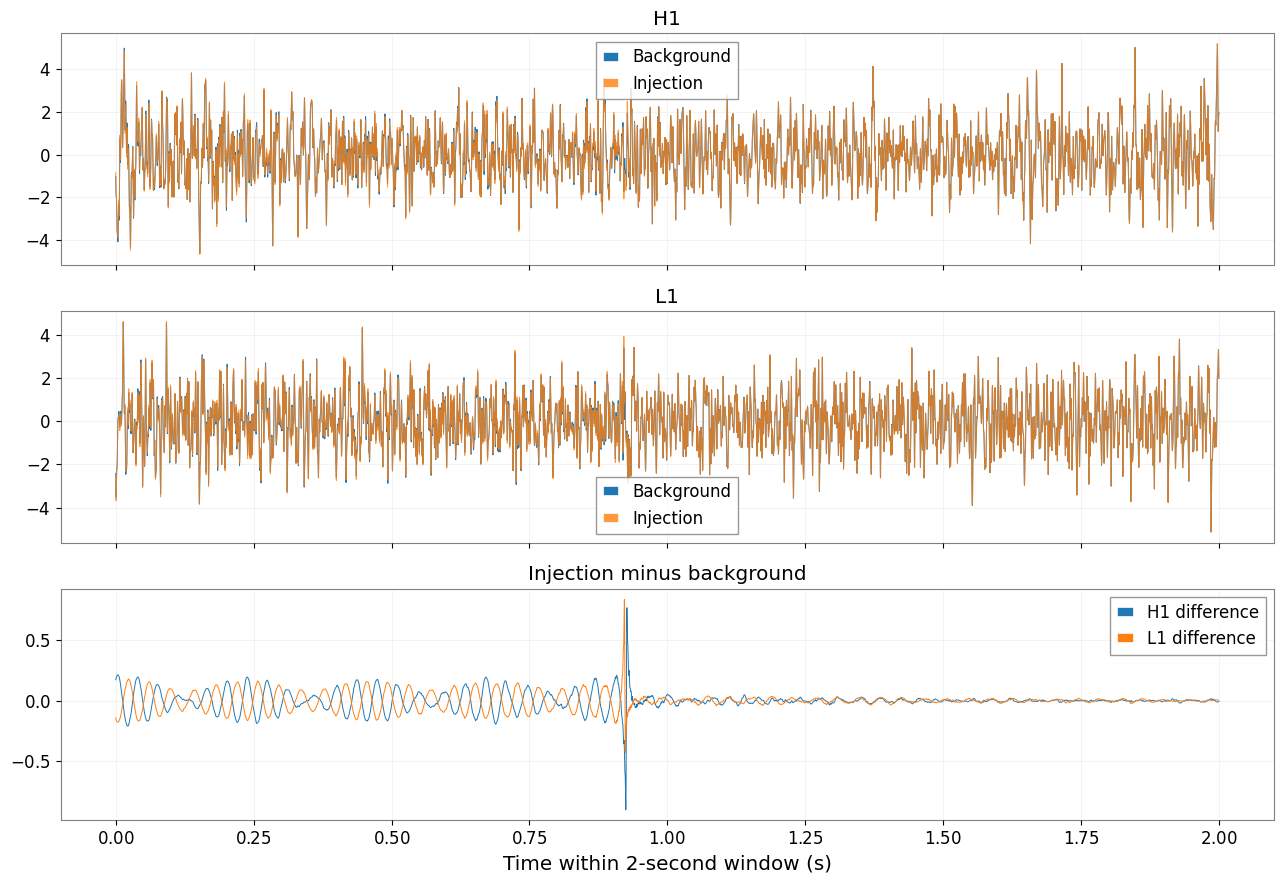

In [36]:
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT = Path("/content/gw150914_flagship")
split = "test"

with np.load(PROJECT / f"dataset/gw150914_{split}_v2.npz") as d:
    X, y = d["X"].astype(np.float64), d["y"]

records = json.loads(
    (PROJECT / f"reports/gw150914_{split}_v2_metadata.json").read_text()
)

# Choose an injection and locate its matching background by pair_id
pos_idx = next(i for i, r in enumerate(records) if r["label"] == 1)
pos_rec = records[pos_idx]

neg_idx = next(
    (i for i, r in enumerate(records)
     if r["label"] == 0
     and r["pair_id"] == pos_rec["pair_id"]
     and r["background_offset_seconds"] == pos_rec["background_offset_seconds"]),
    None
)

print("Positive record:", {
    "index": pos_idx,
    "pair_id": pos_rec["pair_id"],
    "offset": pos_rec["background_offset_seconds"],
    "context_start_sample": pos_rec["context_start_sample"],
    "injection": pos_rec["injection"]
})

if neg_idx is None:
    print("No matching negative sample found; cannot use a paired difference.")
else:
    neg_rec = records[neg_idx]
    print("Negative index:", neg_idx)
    print("Same context start:",
          pos_rec["context_start_sample"] == neg_rec["context_start_sample"])

    t = np.arange(X.shape[2]) / 4096.0
    fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)

    for ch, detector in enumerate(["H1", "L1"]):
        axes[ch].plot(t, X[neg_idx, ch], lw=0.7, label="Background")
        axes[ch].plot(t, X[pos_idx, ch], lw=0.7, alpha=0.8, label="Injection")
        axes[ch].set_title(detector)
        axes[ch].legend()
        axes[ch].grid(alpha=0.2)

        diff = X[pos_idx, ch] - X[neg_idx, ch]
        axes[2].plot(t, diff, lw=0.7, label=f"{detector} difference")

        print(
            detector,
            "| background RMS:", round(np.sqrt(np.mean(X[neg_idx, ch]**2)), 4),
            "| injection RMS:", round(np.sqrt(np.mean(X[pos_idx, ch]**2)), 4),
            "| difference RMS:", round(np.sqrt(np.mean(diff**2)), 4),
            "| difference peak:", round(np.max(np.abs(diff)), 4)
        )

    axes[2].set_title("Injection minus background")
    axes[2].set_xlabel("Time within 2-second window (s)")
    axes[2].legend()
    axes[2].grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

Injection index: 0
Recorded merger sample: 3736
Merger time in window: 0.912109375 seconds
Recorded target norm: 9.441820816537193


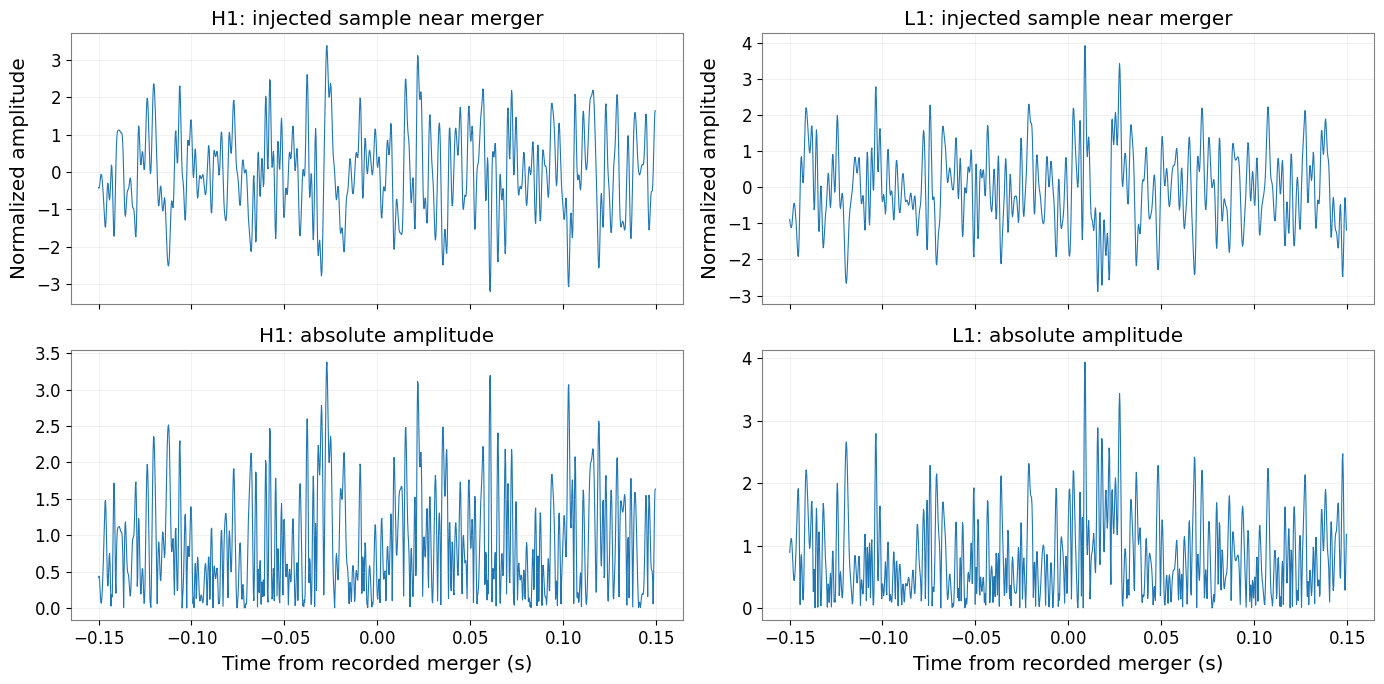

In [37]:
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

P = Path("/content/gw150914_flagship")
split = "test"

with np.load(P / f"dataset/gw150914_{split}_v2.npz") as d:
    X, y = d["X"], d["y"]

records = json.loads(
    (P / f"reports/gw150914_{split}_v2_metadata.json").read_text()
)

# Pick an injection
i = next(i for i, r in enumerate(records) if r["label"] == 1)
r = records[i]
inj = r["injection"]
merger = inj["merger_sample_in_2s_window"]

print("Injection index:", i)
print("Recorded merger sample:", merger)
print("Merger time in window:", merger / 4096, "seconds")
print("Recorded target norm:", inj["target_whitened_signal_norm_not_calibrated_snr"])

# Show 0.15 s on either side of the recorded merger
half = int(0.15 * 4096)
lo, hi = max(0, merger-half), min(X.shape[2], merger+half)
t = (np.arange(lo, hi) - merger) / 4096

fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True)

for ch, detector in enumerate(["H1", "L1"]):
    signal = X[i, ch, lo:hi]
    axes[0, ch].plot(t, signal, lw=0.8)
    axes[0, ch].set_title(f"{detector}: injected sample near merger")
    axes[0, ch].set_ylabel("Normalized amplitude")
    axes[0, ch].grid(alpha=0.25)

    # Plot absolute amplitude to make peaks easier to inspect
    axes[1, ch].plot(t, np.abs(signal), lw=0.8)
    axes[1, ch].set_title(f"{detector}: absolute amplitude")
    axes[1, ch].set_xlabel("Time from recorded merger (s)")
    axes[1, ch].grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [38]:
import json
import numpy as np
from pathlib import Path

P = Path("/content/gw150914_flagship")
split = "test"

with np.load(P / f"dataset/gw150914_{split}_v2.npz") as d:
    X, y = d["X"], d["y"]

records = json.loads(
    (P / f"reports/gw150914_{split}_v2_metadata.json").read_text()
)

i = next(i for i, r in enumerate(records) if r["label"] == 1)
r = records[i]
merger = r["injection"]["merger_sample_in_2s_window"]

print("Injection index:", i, "| merger sample:", merger)

for ch, detector in enumerate(["H1", "L1"]):
    x = X[i, ch].astype(float)

    print(f"\n{detector}")
    print("Whole-window RMS:", round(np.sqrt(np.mean(x**2)), 5))
    print("Whole-window peak:", round(np.max(np.abs(x)), 5))

    for radius_ms in [10, 25, 50, 100, 150]:
        radius = int(radius_ms * 4096 / 1000)
        lo, hi = max(0, merger-radius), min(len(x), merger+radius)
        local = x[lo:hi]
        print(
            f"±{radius_ms:3d} ms: "
            f"RMS={np.sqrt(np.mean(local**2)):.5f}, "
            f"peak={np.max(np.abs(local)):.5f}"
        )

Injection index: 0 | merger sample: 3736

H1
Whole-window RMS: 1.20941
Whole-window peak: 5.1466
± 10 ms: RMS=0.86161, peak=2.06767
± 25 ms: RMS=1.13790, peak=3.10965
± 50 ms: RMS=1.23316, peak=3.37550
±100 ms: RMS=1.10669, peak=3.37550
±150 ms: RMS=1.12478, peak=3.37550

L1
Whole-window RMS: 1.15901
Whole-window peak: 5.13909
± 10 ms: RMS=1.35039, peak=3.93727
± 25 ms: RMS=1.31975, peak=3.93727
± 50 ms: RMS=1.20339, peak=3.93727
±100 ms: RMS=1.05882, peak=3.93727
±150 ms: RMS=1.05304, peak=3.93727
